# Questões 3 e 4 — CIFAR-10: MLP vs. CNN e interpretação das representações

**Disciplina:** Aprendizado Profundo — UFPB/CI — 2026.2 — Prof. Tiago Maritan

## Objetivo
- **Q3:** treinar dois classificadores para o CIFAR-10 — uma **MLP** e uma **CNN** — e comparar arquitetura, curvas de erro, matriz de confusão e acurácia no teste.
- **Q4:** "abrir a caixa-preta" da CNN: filtros da 1ª camada, mapas de ativação de uma camada intermediária, análise de acertos/erros com probabilidades e como essas representações evoluem ao longo do treinamento (item d).

## O dataset
CIFAR-10 tem **60.000 imagens coloridas 32×32** em **10 classes** balanceadas (6.000 por classe): avião, automóvel, pássaro, gato, cervo, cachorro, sapo, cavalo, navio e caminhão.
Divisão oficial: 50.000 treino / 10.000 teste. Separamos **5.000 imagens do treino para validação** (o teste só é usado no final, para não "vazar" informação na escolha de hiperparâmetros).

## Ideia central (por que esperar que a CNN vença?)
Uma MLP recebe a imagem "achatada" num vetor de 3.072 números (32·32·3). Ela **não sabe** que pixels vizinhos estão relacionados: trocar a ordem dos pixels (sempre da mesma forma) não muda nada para ela. Ela precisa aprender tudo do zero e tem muitos parâmetros.

A CNN incorpora dois **vieses indutivos** adequados a imagens:
1. **Conectividade local** — cada neurônio olha apenas uma vizinhança (ex.: 3×3), porque padrões visuais (bordas, texturas) são locais.
2. **Compartilhamento de pesos** — o mesmo filtro percorre a imagem inteira: um detector de borda útil no canto também é útil no centro (equivariância à translação).

Empilhando camadas + pooling, o campo receptivo cresce e a rede compõe hierarquias: bordas → texturas → partes → objetos.

## 1. Configuração e reprodutibilidade

In [1]:
import os, pickle, time, copy, random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path(os.environ.get("DATA_DIR", "../data"))
FIG_DIR = Path("../figuras"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("../modelos"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]
print("Dispositivo:", DEVICE, "| PyTorch", torch.__version__)

Dispositivo: cpu | PyTorch 2.15.0+cu132


## 2. Carregamento dos dados
Lemos os arquivos originais (`cifar-10-batches-py`). Se não existirem localmente, o `torchvision` baixa do site oficial (funciona no Colab).
Cada imagem vem como vetor de 3.072 bytes no formato **canal-primeiro** (1.024 R, 1.024 G, 1.024 B) → remodelamos para `(N, 3, 32, 32)`.

In [2]:
def load_cifar10(root: Path):
    """Retorna (X_train, y_train, X_test, y_test) como tensores uint8 (N,3,32,32) e int64."""
    folder = root / "cifar-10-batches-py"
    if not folder.exists():
        import torchvision
        torchvision.datasets.CIFAR10(root=str(root), train=True, download=True)
    def read(name):
        with open(folder / name, "rb") as f:
            d = pickle.load(f, encoding="bytes")
        return d[b"data"].reshape(-1, 3, 32, 32), np.array(d[b"labels"])
    parts = [read(f"data_batch_{i}") for i in range(1, 6)]
    Xtr = np.concatenate([p[0] for p in parts]); ytr = np.concatenate([p[1] for p in parts])
    Xte, yte = read("test_batch")
    return (torch.from_numpy(Xtr), torch.from_numpy(ytr).long(),
            torch.from_numpy(Xte), torch.from_numpy(yte).long())

Xtr_u8, ytr_all, Xte_u8, yte = load_cifar10(DATA_DIR)
print("Treino:", tuple(Xtr_u8.shape), "| Teste:", tuple(Xte_u8.shape))
print("Imagens por classe (treino):", np.bincount(ytr_all.numpy()))

Treino: (50000, 3, 32, 32) | Teste: (10000, 3, 32, 32)
Imagens por classe (treino): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


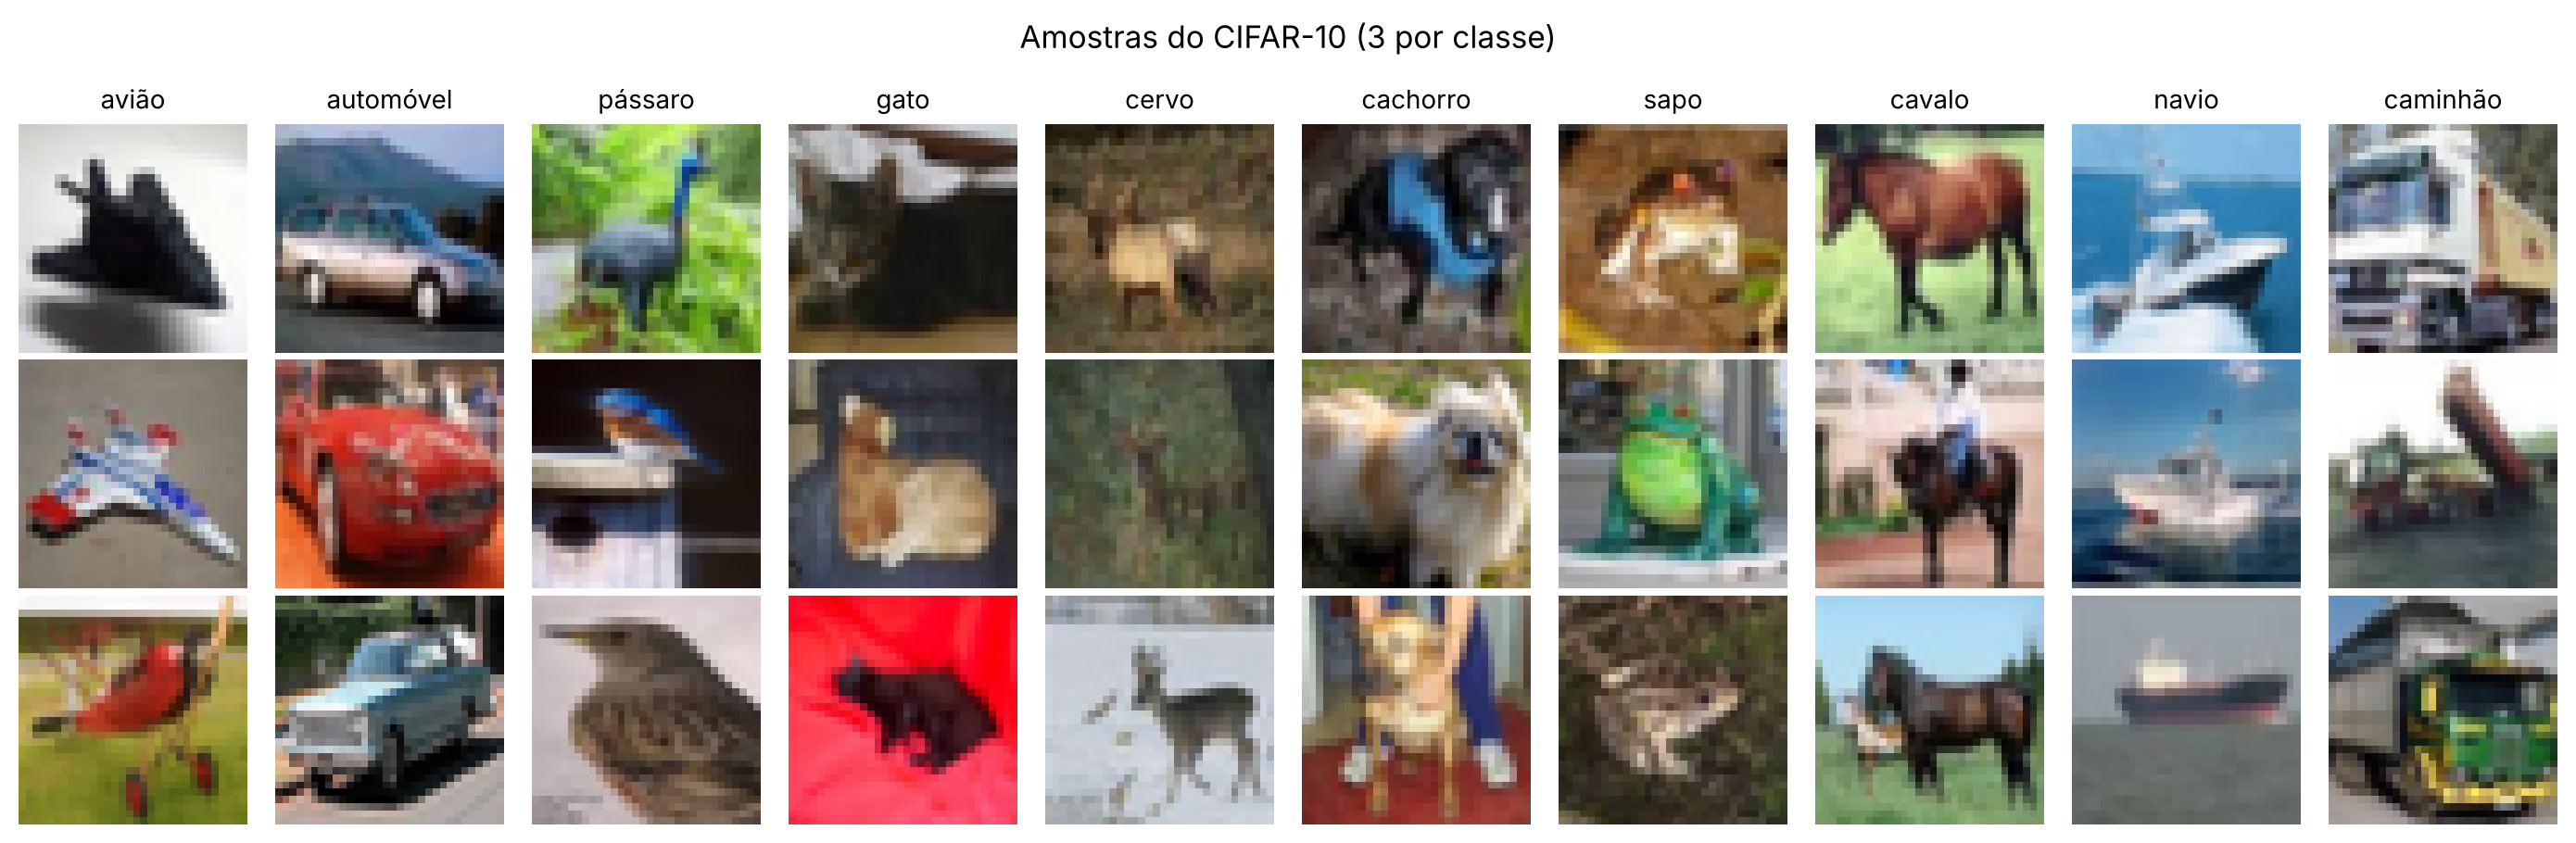

In [3]:
fig, axes = plt.subplots(3, 10, figsize=(14, 4.6))
for c in range(10):
    idx = np.where(ytr_all.numpy() == c)[0][:3]
    for r, i in enumerate(idx):
        axes[r, c].imshow(Xtr_u8[i].permute(1, 2, 0).numpy()); axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=10)
plt.suptitle("Amostras do CIFAR-10 (3 por classe)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q3_amostras.png", dpi=120); plt.show()

### Pré-processamento
1. **Escala [0,1]** e depois **padronização por canal** (subtrai média e divide pelo desvio de cada canal RGB, calculados **só no treino**). Entradas centradas em zero e com variância parecida deixam o gradiente mais bem-comportado e aceleram a convergência.
2. **Split treino/validação** estratificado: 45.000 / 5.000.
3. **Data augmentation (só na CNN, só no treino):** *random crop* com padding 4 e *flip* horizontal. Isso cria variações plausíveis (um gato espelhado continua sendo gato) e funciona como regularização, reduzindo overfitting.

In [4]:
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(ytr_all), generator=g)
val_idx, tr_idx = perm[:5000], perm[5000:]
Xtr = Xtr_u8[tr_idx].float() / 255.; ytr = ytr_all[tr_idx]
Xva = Xtr_u8[val_idx].float() / 255.; yva = ytr_all[val_idx]
Xte = Xte_u8.float() / 255.

MEAN = Xtr.mean(dim=(0, 2, 3), keepdim=True); STD = Xtr.std(dim=(0, 2, 3), keepdim=True)
norm = lambda x: (x - MEAN) / STD
Xtr_n, Xva_n, Xte_n = norm(Xtr), norm(Xva), norm(Xte)
print("Média por canal:", MEAN.flatten().numpy().round(3), "| Desvio:", STD.flatten().numpy().round(3))
print(f"Treino {len(ytr)} | Validação {len(yva)} | Teste {len(yte)}")

def augment(x: torch.Tensor) -> torch.Tensor:
    """Random crop 32x32 (padding 4, reflexão) + flip horizontal aleatório, em lote."""
    n = x.size(0)
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    i = torch.randint(0, 9, (n,)); j = torch.randint(0, 9, (n,))
    out = torch.stack([xp[k, :, i[k]:i[k] + 32, j[k]:j[k] + 32] for k in range(n)])
    flip = torch.rand(n) < 0.5
    out[flip] = out[flip].flip(-1)
    return out

Média por canal: [0.491 0.482 0.447] | Desvio: [0.247 0.244 0.262]
Treino 45000 | Validação 5000 | Teste 10000


## 3. Funções de treino e avaliação (reutilizadas pelos dois modelos)
- **Perda:** entropia cruzada (Cross-Entropy), a escolha padrão para classificação multiclasse: mede a distância entre a distribuição prevista pelo softmax e a classe real (one-hot). Uso *label smoothing* = 0,05 na CNN para evitar excesso de confiança.
- **Otimizador:** AdamW (Adam com *weight decay* desacoplado = regularização L2).
- **Agenda de taxa de aprendizado:** OneCycle — começa baixa, sobe e depois decai até quase zero; costuma convergir mais rápido e melhor que LR fixo.
- **Seleção do modelo:** guardamos os pesos da época com **maior acurácia de validação** (equivalente a *early stopping* por checkpoint).

In [5]:
def evaluate(model, X, y, bs=1000):
    model.eval(); losses, preds, probs = [], [], []
    with torch.no_grad():
        for k in range(0, len(y), bs):
            xb, yb = X[k:k + bs].to(DEVICE), y[k:k + bs].to(DEVICE)
            out = model(xb)
            losses.append(F.cross_entropy(out, yb, reduction="sum").item())
            p = out.softmax(1); probs.append(p.cpu()); preds.append(p.argmax(1).cpu())
    preds = torch.cat(preds); probs = torch.cat(probs)
    return sum(losses) / len(y), (preds == y).float().mean().item(), preds, probs

def train(model, epochs, lr, bs=128, wd=5e-4, aug=False, smoothing=0.0, name="modelo"):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * ((len(ytr) + bs - 1) // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_acc, best_state = 0, None
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); tl, tc = 0.0, 0
        perm = torch.randperm(len(ytr))
        for k in range(0, len(ytr), bs):
            idx = perm[k:k + bs]
            xb = Xtr_n[idx]; xb = augment(xb) if aug else xb
            xb, yb = xb.to(DEVICE), ytr[idx].to(DEVICE)
            out = model(xb); loss = F.cross_entropy(out, yb, label_smoothing=smoothing)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl += F.cross_entropy(out, yb, reduction="sum").item(); tc += (out.argmax(1) == yb).sum().item()
        vl, va, _, _ = evaluate(model, Xva_n, yva)
        hist["train_loss"].append(tl / len(ytr)); hist["train_acc"].append(tc / len(ytr))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if va > best_acc: best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] época {ep:02d}/{epochs} | perda treino {hist['train_loss'][-1]:.4f} | perda val {vl:.4f} "
              f"| acc treino {hist['train_acc'][-1]:.3f} | acc val {va:.3f} | {time.time() - t0:.0f}s")
    model.load_state_dict(best_state)
    print(f"Melhor acurácia de validação: {best_acc:.4f}")
    return hist

def plot_history(hist, title, fname):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist["train_loss"], "o-", ms=3, label="Treino"); ax[0].plot(ep, hist["val_loss"], "s-", ms=3, label="Validação")
    ax[0].set(title=f"{title} — Erro (cross-entropy)", xlabel="Época", ylabel="Perda"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], "o-", ms=3, label="Treino"); ax[1].plot(ep, hist["val_acc"], "s-", ms=3, label="Validação")
    ax[1].set(title=f"{title} — Acurácia", xlabel="Época", ylabel="Acurácia"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=120); plt.show()

def plot_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    cmn = cm / cm.sum(1, keepdims=True)
    plt.figure(figsize=(9, 7.5))
    sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, cbar_kws={"label": "proporção da classe real"})
    plt.xlabel("Classe predita"); plt.ylabel("Classe real"); plt.title(title)
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=120); plt.show()

count_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)

## 4. Questão 3(a) — MLP

### Arquitetura
| Camada | Saída | Detalhes |
|---|---|---|
| Flatten | 3.072 | 32×32×3 → vetor |
| Linear + BatchNorm + ReLU + Dropout(0,3) | 1.024 | |
| Linear + BatchNorm + ReLU + Dropout(0,3) | 512 | |
| Linear + BatchNorm + ReLU + Dropout(0,3) | 256 | |
| Linear | 10 | logits → softmax na perda |

**Por que essas escolhas?**
- **ReLU**: não satura para valores positivos → evita o desaparecimento do gradiente das sigmoides em redes profundas.
- **Batch Normalization**: normaliza as ativações de cada mini-lote; estabiliza e acelera o treino, permitindo LR maiores.
- **Dropout**: desliga aleatoriamente 30% dos neurônios no treino, forçando representações redundantes → reduz overfitting (muito relevante numa MLP com milhões de parâmetros).

In [6]:
class MLP(nn.Module):
    def __init__(self, sizes=(3072, 1024, 512, 256), n_classes=10, p=0.3):
        super().__init__()
        layers = [nn.Flatten()]
        for a, b in zip(sizes[:-1], sizes[1:]):
            layers += [nn.Linear(a, b), nn.BatchNorm1d(b), nn.ReLU(inplace=True), nn.Dropout(p)]
        layers.append(nn.Linear(sizes[-1], n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

torch.manual_seed(SEED)
mlp = MLP()
print(mlp); print(f"Parâmetros treináveis: {count_params(mlp):,}")

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=1024, out_features=512, bias=True)
    (6): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=512, out_features=256, bias=True)
    (10): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=256, out_features=10, bias=True)
  )
)
Parâmetros treináveis: 3,809,034


[MLP] época 01/25 | perda treino 1.9313 | perda val 1.6819 | acc treino 0.316 | acc val 0.413 | 8s


[MLP] época 02/25 | perda treino 1.6511 | perda val 1.5158 | acc treino 0.417 | acc val 0.465 | 8s


[MLP] época 03/25 | perda treino 1.5357 | perda val 1.4584 | acc treino 0.452 | acc val 0.482 | 8s


[MLP] época 04/25 | perda treino 1.4740 | perda val 1.3998 | acc treino 0.472 | acc val 0.498 | 8s


[MLP] época 05/25 | perda treino 1.4174 | perda val 1.3694 | acc treino 0.493 | acc val 0.509 | 8s


[MLP] época 06/25 | perda treino 1.3732 | perda val 1.3529 | acc treino 0.512 | acc val 0.517 | 8s


... (15 outputs left out)

[MLP] época 22/25 | perda treino 0.7044 | perda val 1.2077 | acc treino 0.750 | acc val 0.596 | 8s


[MLP] época 23/25 | perda treino 0.6830 | perda val 1.2094 | acc treino 0.758 | acc val 0.593 | 7s


[MLP] época 24/25 | perda treino 0.6622 | perda val 1.2138 | acc treino 0.765 | acc val 0.592 | 8s


[MLP] época 25/25 | perda treino 0.6591 | perda val 1.2098 | acc treino 0.766 | acc val 0.592 | 8s
Melhor acurácia de validação: 0.5964


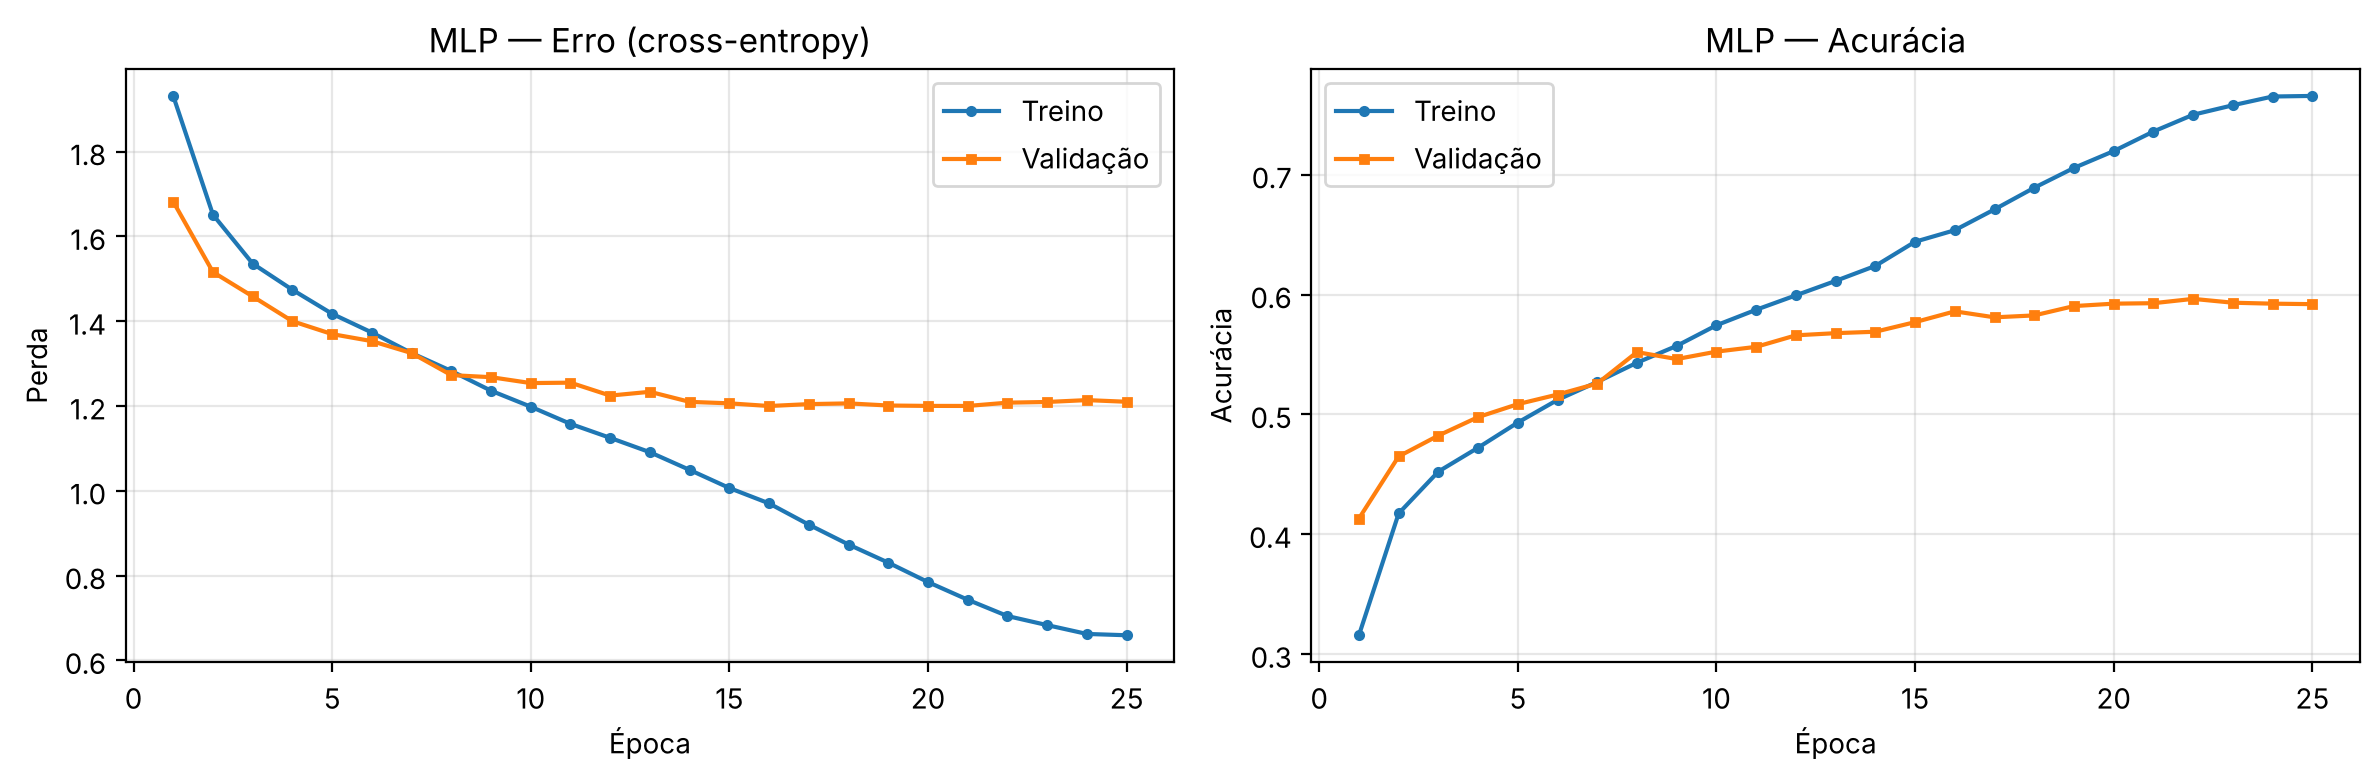

In [7]:
MLP_EPOCHS = int(os.environ.get("MLP_EPOCHS", 25))
hist_mlp = train(mlp, epochs=MLP_EPOCHS, lr=1e-3, bs=256, wd=1e-4, name="MLP")
plot_history(hist_mlp, "MLP", "q3_mlp_curvas.png")

Acurácia da MLP no TESTE: 0.5943


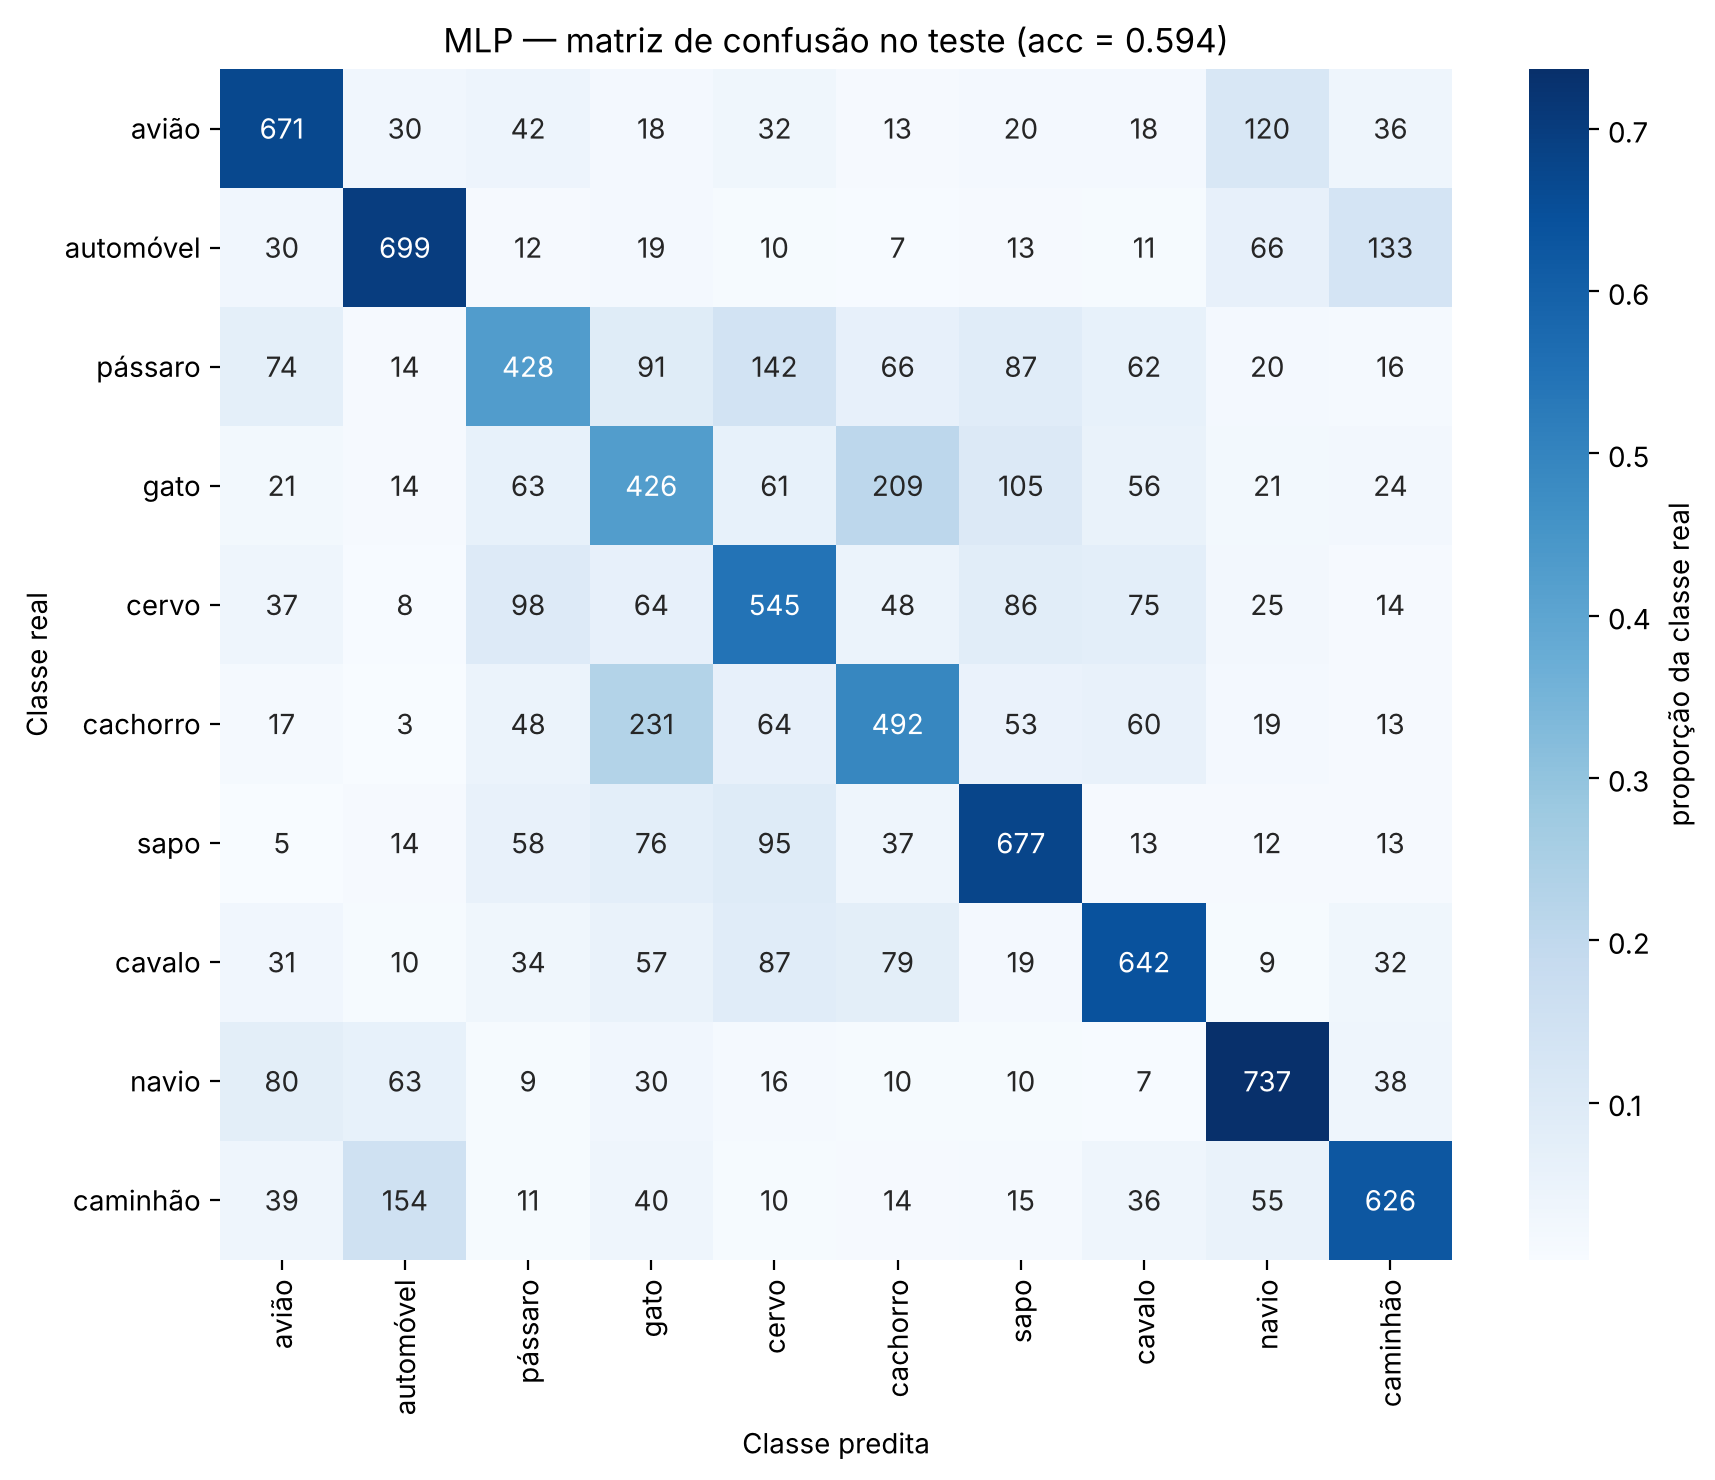

              precision    recall  f1-score   support

       avião      0.668     0.671     0.669      1000
   automóvel      0.693     0.699     0.696      1000
     pássaro      0.533     0.428     0.475      1000
        gato      0.405     0.426     0.415      1000
       cervo      0.513     0.545     0.529      1000
    cachorro      0.505     0.492     0.498      1000
        sapo      0.624     0.677     0.649      1000
      cavalo      0.655     0.642     0.648      1000
       navio      0.680     0.737     0.707      1000
    caminhão      0.662     0.626     0.644      1000

    accuracy                          0.594     10000
   macro avg      0.594     0.594     0.593     10000
weighted avg      0.594     0.594     0.593     10000



In [8]:
_, acc_mlp, pred_mlp, prob_mlp = evaluate(mlp, Xte_n, yte)
print(f"Acurácia da MLP no TESTE: {acc_mlp:.4f}")
plot_confusion(yte, pred_mlp, f"MLP — matriz de confusão no teste (acc = {acc_mlp:.3f})", "q3_mlp_confusao.png")
print(classification_report(yte, pred_mlp, target_names=CLASSES, digits=3))

## 5. Questão 3(b) — CNN

### Arquitetura (estilo VGG)
| Bloco | Camadas | Saída |
|---|---|---|
| Entrada | | 3×32×32 |
| **conv1** | Conv 5×5, 32 filtros + BN + ReLU | 32×32×32 |
| Bloco 1 | Conv 3×3 (32) + BN + ReLU → MaxPool 2×2 → Dropout2d(0,1) | 32×16×16 |
| Bloco 2 | Conv 3×3 (64) + BN + ReLU ×2 → MaxPool 2×2 → Dropout2d(0,1) | 64×8×8 |
| Bloco 3 | Conv 3×3 (128) + BN + ReLU ×2 → MaxPool 2×2 → Dropout2d(0,1) | 128×4×4 |
| Classificador | Flatten → Linear 256 + BN + ReLU + Dropout(0,4) → Linear 10 | 10 |

**Decisões de projeto:**
- **1ª convolução 5×5** (em vez de 3×3) de propósito: filtros maiores ficam mais "legíveis" na visualização da Q4(a).
- **Pares de conv 3×3**: duas 3×3 empilhadas têm o mesmo campo receptivo de uma 5×5, com menos parâmetros e mais uma não-linearidade (ideia do VGG).
- **MaxPool** reduz a resolução pela metade: diminui custo, aumenta o campo receptivo e dá pequena invariância a deslocamentos.
- **Número de filtros dobra** quando a resolução cai: a rede troca "onde" por "o quê" (mais canais semânticos, menos detalhe espacial).
- Regularização: data augmentation + BN + dropout + weight decay + label smoothing.

In [9]:
def conv_bn(i, o, k=3):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.conv1 = conv_bn(3, 32, k=5)
        self.block1 = nn.Sequential(conv_bn(32, 32), nn.MaxPool2d(2), nn.Dropout2d(0.1))
        self.block2 = nn.Sequential(conv_bn(32, 64), conv_bn(64, 64), nn.MaxPool2d(2), nn.Dropout2d(0.1))
        self.block3 = nn.Sequential(conv_bn(64, 128), conv_bn(128, 128), nn.MaxPool2d(2), nn.Dropout2d(0.1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128 * 4 * 4, 256, bias=False), nn.BatchNorm1d(256),
                                        nn.ReLU(inplace=True), nn.Dropout(0.4), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.classifier(self.block3(self.block2(self.block1(self.conv1(x)))))

torch.manual_seed(SEED)
cnn = CNN()
print(cnn); print(f"Parâmetros treináveis: {count_params(cnn):,}  (MLP: {count_params(mlp):,})")

CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (block1): Sequential(
    (0): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Dropout2d(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1),

Pesos e histórico carregados de ../modelos (treino original: 25 épocas, ~40 min em CPU). Log do treino:
[CNN] época 01 | perda treino 1.7367 | perda val 1.3224 | acc treino 0.371 | acc val 0.541
[CNN] época 02 | perda treino 1.4033 | perda val 1.1001 | acc treino 0.499 | acc val 0.623
[CNN] época 03 | perda treino 1.1988 | perda val 0.9004 | acc treino 0.580 | acc val 0.699
[CNN] época 04 | perda treino 1.0574 | perda val 0.9000 | acc treino 0.633 | acc val 0.679
[CNN] época 05 | perda treino 0.9650 | perda val 0.7974 | acc treino 0.668 | acc val 0.724
[CNN] época 06 | perda treino 0.8890 | perda val 0.7526 | acc treino 0.698 | acc val 0.738
[CNN] época 07 | perda treino 0.8292 | perda val 0.6889 | acc treino 0.721 | acc val 0.764
[CNN] época 08 | perda treino 0.7702 | perda val 0.6034 | acc treino 0.743 | acc val 0.801
[CNN] época 09 | perda treino 0.7268 | perda val 0.5618 | acc treino 0.757 | acc val 0.819
[CNN] época 10 | perda treino 0.6877 | perda val 0.5233 | acc treino 0.776 | 

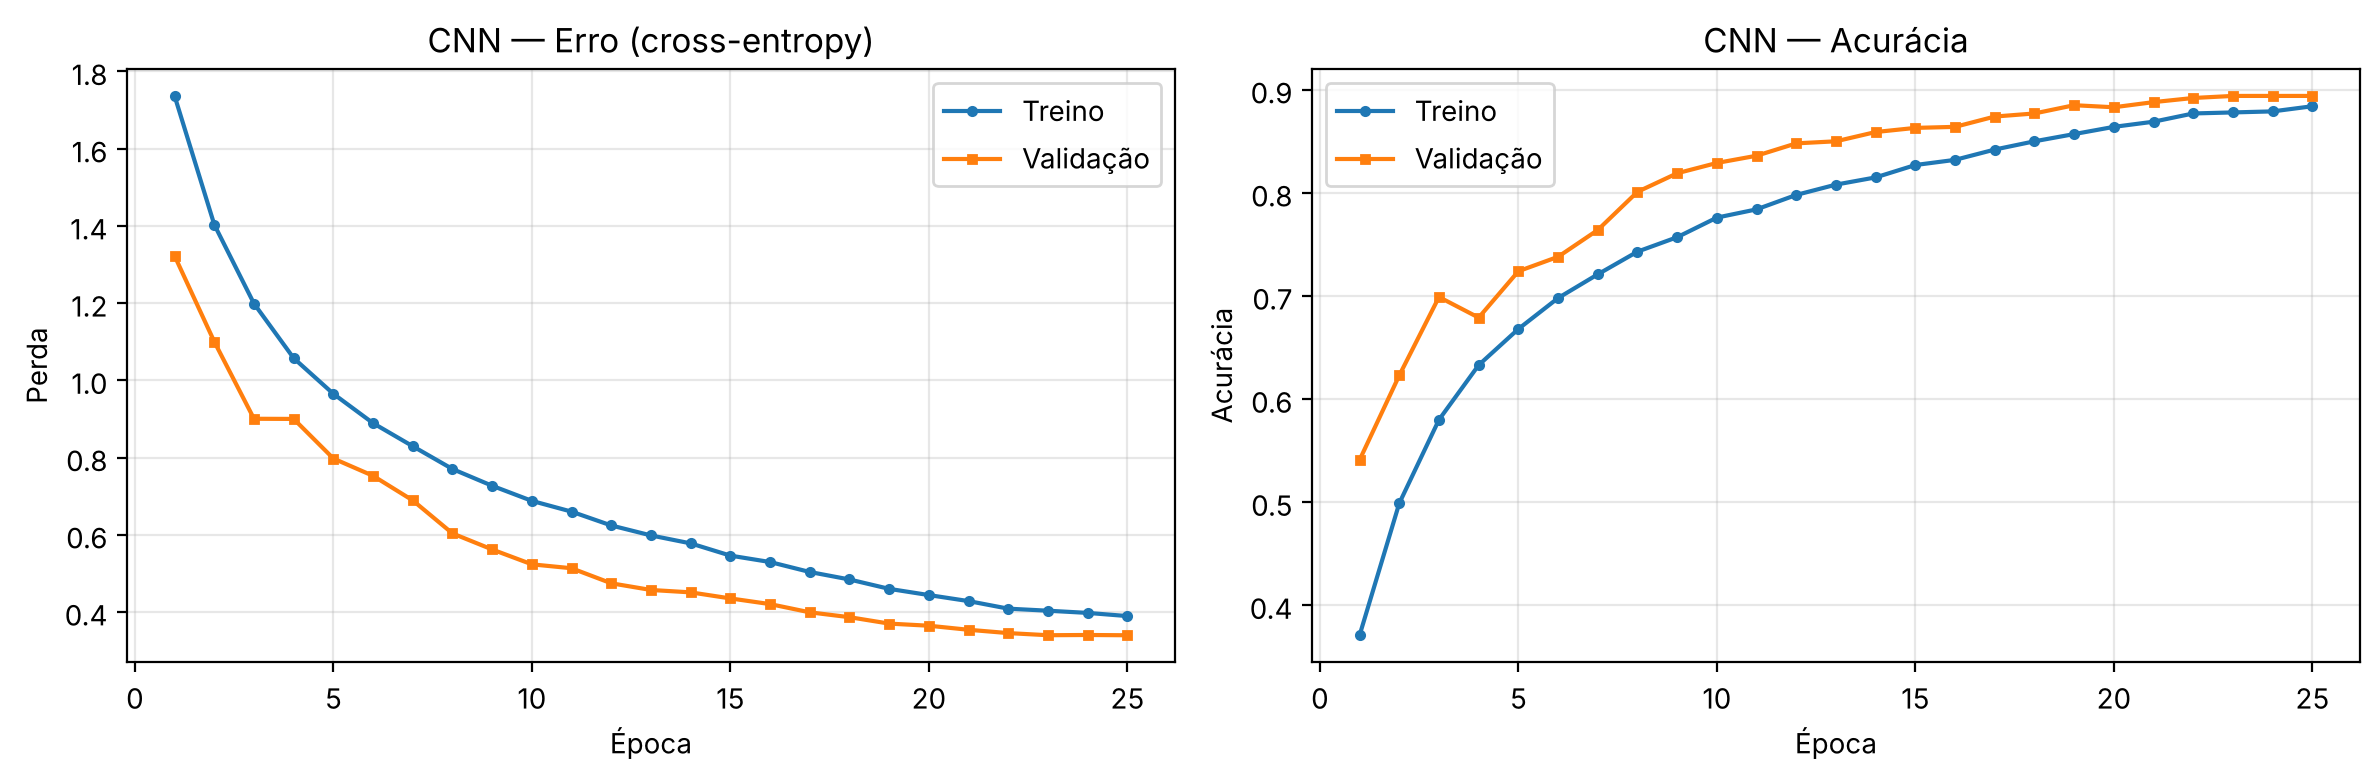

In [10]:
# Treinar a CNN leva ~40 min em CPU (poucos minutos em GPU). Se os pesos e o histórico já existirem em ../modelos,
# eles são carregados (a Q4 pode ser refeita sem retreinar). Para forçar o treino: RETRAIN=1.
import json
CNN_EPOCHS = int(os.environ.get("CNN_EPOCHS", 25))
w_path, h_path = MODEL_DIR / "cnn_cifar10.pt", MODEL_DIR / "hist_cnn.json"
if w_path.exists() and h_path.exists() and os.environ.get("RETRAIN", "0") != "1":
    cnn.load_state_dict(torch.load(w_path, map_location=DEVICE)); cnn.to(DEVICE)
    hist_cnn = json.load(open(h_path))
    print(f"Pesos e histórico carregados de {MODEL_DIR} (treino original: {len(hist_cnn['val_acc'])} épocas, ~40 min em CPU). Log do treino:")
    for i, (tl, vl, ta, va) in enumerate(zip(*[hist_cnn[k] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]]), 1):
        print(f"[CNN] época {i:02d} | perda treino {tl:.4f} | perda val {vl:.4f} | acc treino {ta:.3f} | acc val {va:.3f}")
else:
    hist_cnn = train(cnn, epochs=CNN_EPOCHS, lr=3e-3, bs=128, wd=5e-4, aug=True, smoothing=0.05, name="CNN")
    torch.save(cnn.state_dict(), w_path); json.dump(hist_cnn, open(h_path, "w"))
plot_history(hist_cnn, "CNN", "q3_cnn_curvas.png")

> **Leitura das curvas:** com data augmentation, a perda de **treino** é medida em imagens aumentadas (mais difíceis) e com dropout ativo, por isso pode ficar **acima** da de validação nas primeiras épocas — isso não é erro, é efeito da regularização. O que importa é a validação continuar caindo e o gap treino/validação ficar pequeno ao final.

Acurácia da CNN no TESTE: 0.8885


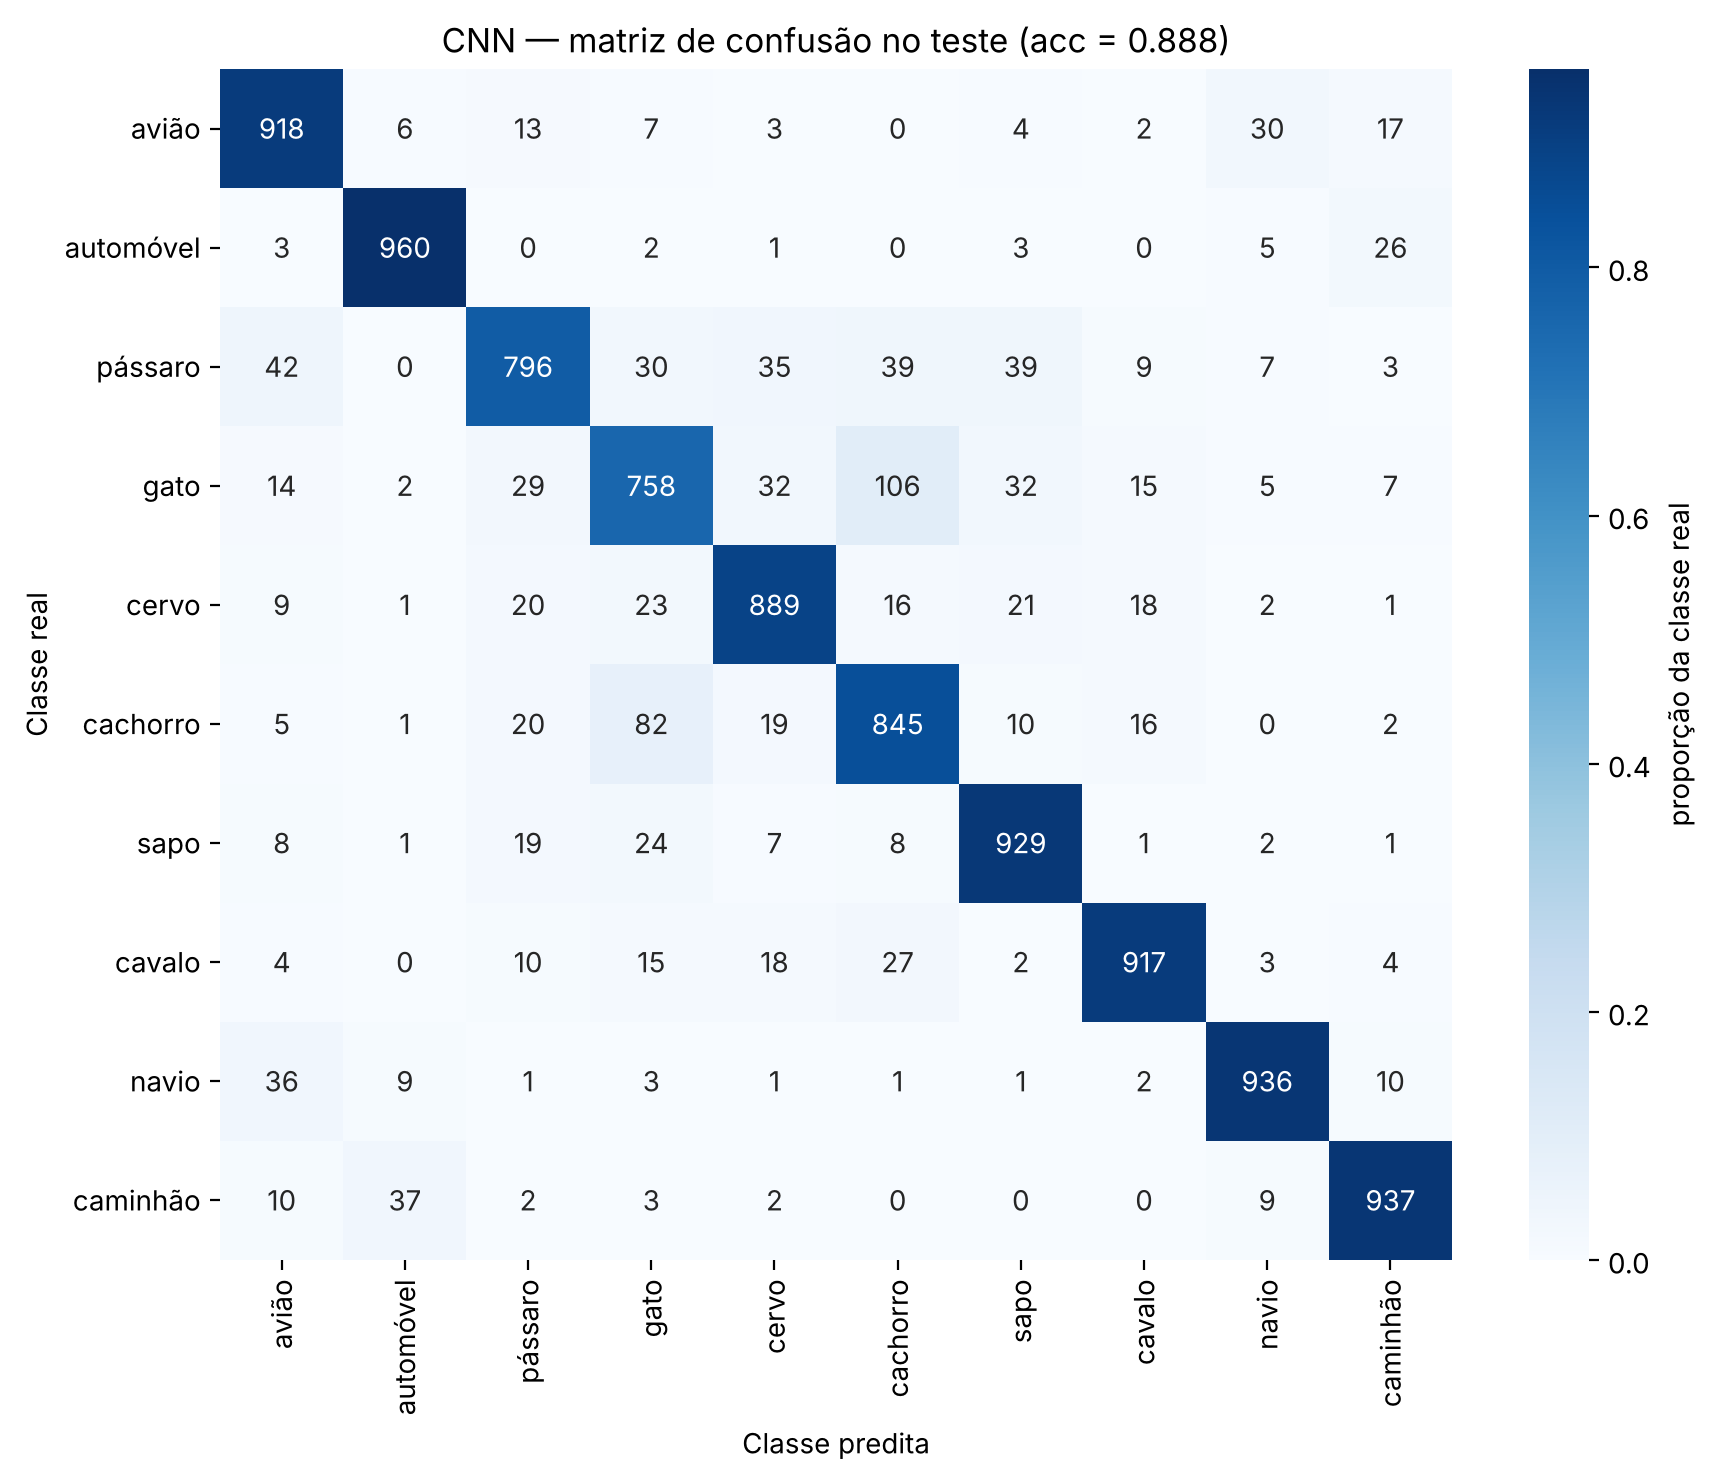

              precision    recall  f1-score   support

       avião      0.875     0.918     0.896      1000
   automóvel      0.944     0.960     0.952      1000
     pássaro      0.875     0.796     0.834      1000
        gato      0.800     0.758     0.779      1000
       cervo      0.883     0.889     0.886      1000
    cachorro      0.811     0.845     0.828      1000
        sapo      0.892     0.929     0.910      1000
      cavalo      0.936     0.917     0.926      1000
       navio      0.937     0.936     0.936      1000
    caminhão      0.930     0.937     0.933      1000

    accuracy                          0.888     10000
   macro avg      0.888     0.888     0.888     10000
weighted avg      0.888     0.888     0.888     10000



In [11]:
_, acc_cnn, pred_cnn, prob_cnn = evaluate(cnn, Xte_n, yte)
print(f"Acurácia da CNN no TESTE: {acc_cnn:.4f}")
plot_confusion(yte, pred_cnn, f"CNN — matriz de confusão no teste (acc = {acc_cnn:.3f})", "q3_cnn_confusao.png")
print(classification_report(yte, pred_cnn, target_names=CLASSES, digits=3))

## 6. Comparação MLP × CNN

,Modelo,Parâmetros,Acurácia teste,F1 macro teste,Melhor acc validação
0,MLP,"3,809,034",0.5943,0.5931,0.5964
1,CNN,"816,362",0.8885,0.8880,0.8940


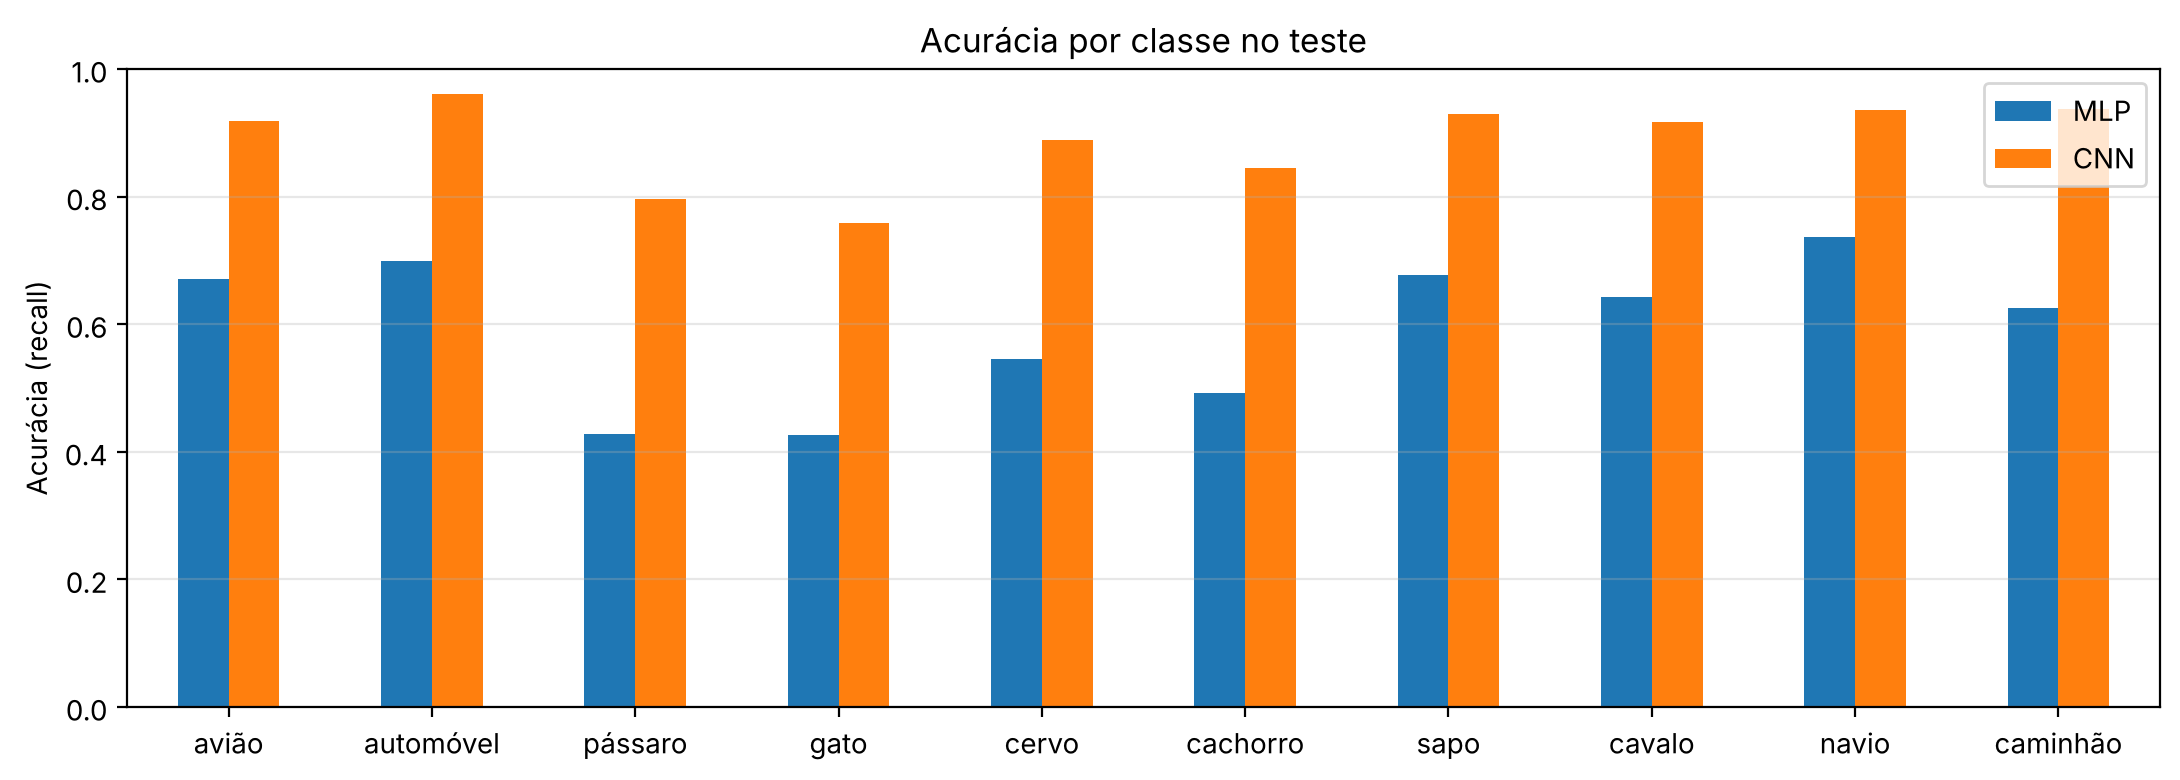

In [12]:
import pandas as pd
from sklearn.metrics import f1_score
comp = pd.DataFrame({
    "Modelo": ["MLP", "CNN"],
    "Parâmetros": [count_params(mlp), count_params(cnn)],
    "Acurácia teste": [acc_mlp, acc_cnn],
    "F1 macro teste": [f1_score(yte, pred_mlp, average="macro"), f1_score(yte, pred_cnn, average="macro")],
    "Melhor acc validação": [max(hist_mlp["val_acc"]), max(hist_cnn["val_acc"])],
})
display(comp.style.format({"Parâmetros": "{:,}", "Acurácia teste": "{:.4f}", "F1 macro teste": "{:.4f}", "Melhor acc validação": "{:.4f}"}))

per_class = pd.DataFrame({"MLP": confusion_matrix(yte, pred_mlp).diagonal() / 1000,
                          "CNN": confusion_matrix(yte, pred_cnn).diagonal() / 1000}, index=CLASSES)
per_class.plot.bar(figsize=(11, 4), rot=0, title="Acurácia por classe no teste")
plt.ylabel("Acurácia (recall)"); plt.ylim(0, 1); plt.grid(axis="y", alpha=.3); plt.tight_layout()
plt.savefig(FIG_DIR / "q3_comparacao_por_classe.png", dpi=120); plt.show()

### Discussão (Q3)
| | MLP | CNN |
|---|---|---|
| Parâmetros | 3,81 milhões | 0,82 milhão |
| Acurácia no teste | **59,4%** | **88,9%** |
| Acc treino × validação (última época) | 76,6% × 59,2% | 88,4% × 89,4% |

- **A CNN acerta ~30 pontos percentuais a mais usando 4,7× menos parâmetros.** A MLP gasta 3,1 milhões de parâmetros só na primeira camada (3.072 × 1.024) e trata cada pixel como uma variável independente. A CNN reaproveita os mesmos filtros 3×3 em todas as posições.
- **Overfitting:** a MLP abre um gap de ~17 pontos entre treino e validação; sua perda de validação para de cair por volta da época 15 enquanto a de treino continua descendo (ela memoriza pixels). Na CNN as curvas andam juntas até o fim; a acurácia de validação estabiliza em 89,4% nas últimas épocas, quando o agendamento OneCycle leva a taxa de aprendizado a quase zero. Ganhos adicionais exigiriam treinar mais épocas com um novo agendamento (ou uma rede maior).
- **Confusões da CNN (matriz):** o maior erro é **gato ↔ cachorro** (106 gatos chamados de cachorro e 82 cachorros chamados de gato), depois **caminhão ↔ automóvel** (37/26), **navio ↔ avião** (36/30 — fundo azul de céu e de mar) e **pássaro → avião** (42). Os erros seguem a **semelhança visual/semântica**: não são aleatórios.
- **Classes fáceis × difíceis:** automóvel (96%), caminhão, navio, sapo, avião e cavalo passam de 91%; gato (76%) e pássaro (80%) são as mais difíceis — animais com pose, escala e fundo muito variáveis em 32×32. A MLP sofre nas mesmas classes (gato 43%, pássaro 43%), mas com erros muito mais espalhados.

---
# Questão 4 — O que a CNN aprendeu?

> As análises abaixo usam a CNN **final** da Q3. A evolução das representações **ao longo do treinamento** (filtros, mapas de ativação e Grad-CAM nas épocas 0, 1, 2, 5, 10 e 25) está no item **4(d)**, no final desta questão.

## 4(a) Filtros da primeira camada convolucional
A primeira camada recebe **pixels RGB diretamente**, então seus pesos têm a mesma natureza da imagem: cada filtro é um pequeno "patch" 5×5×3 que pode ser exibido como imagem colorida. O neurônio dispara mais quando o trecho da imagem **se parece** com o filtro (produto interno alto).

Para visualizar, normalizamos cada filtro individualmente para [0, 1] (min-max).

Formato dos pesos da conv1: (32, 3, 5, 5)


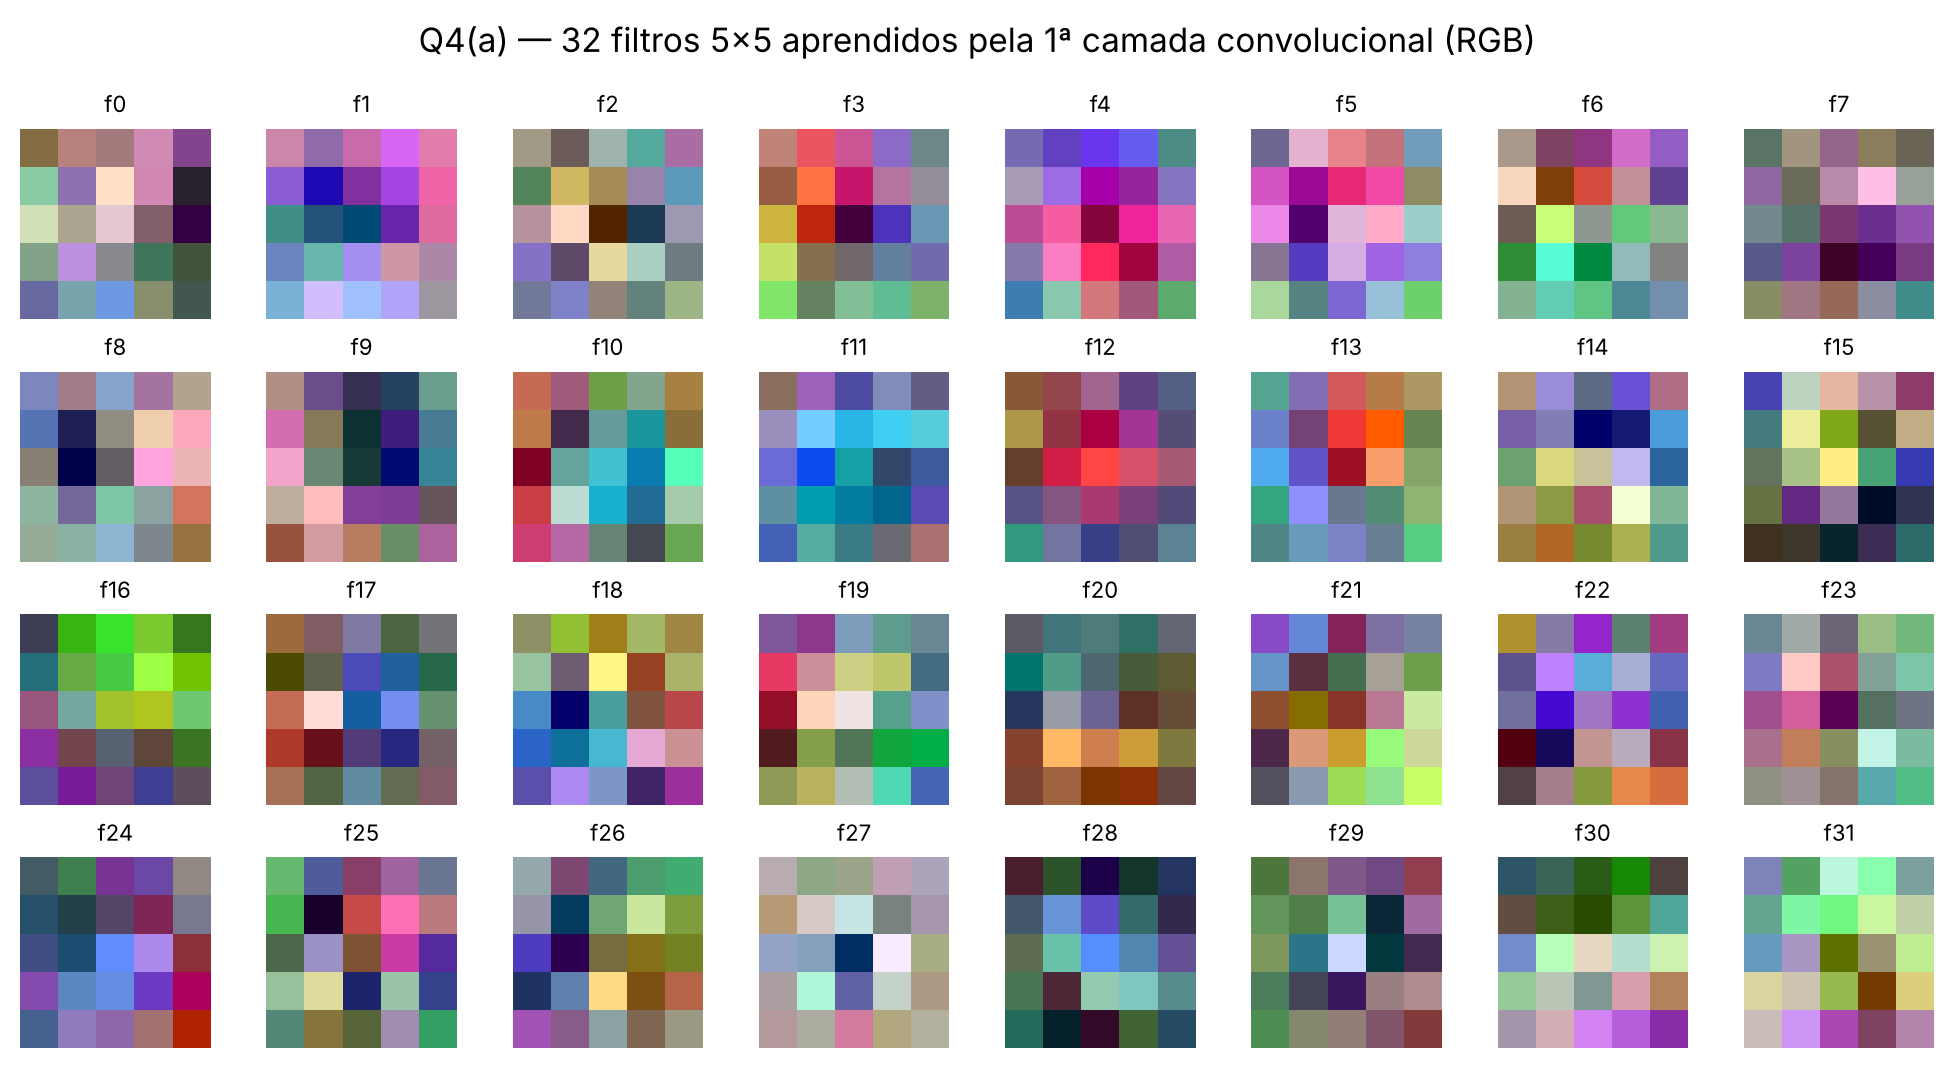

In [13]:
W = cnn.conv1[0].weight.detach().cpu()   # (32, 3, 5, 5)
print("Formato dos pesos da conv1:", tuple(W.shape))
fig, axes = plt.subplots(4, 8, figsize=(10, 5.4))
for i, ax in enumerate(axes.flat):
    w = W[i]; w = (w - w.min()) / (w.max() - w.min() + 1e-8)
    ax.imshow(w.permute(1, 2, 0).numpy(), interpolation="nearest"); ax.set_title(f"f{i}", fontsize=8); ax.axis("off")
plt.suptitle("Q4(a) — 32 filtros 5×5 aprendidos pela 1ª camada convolucional (RGB)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4a_filtros_conv1.png", dpi=140); plt.show()

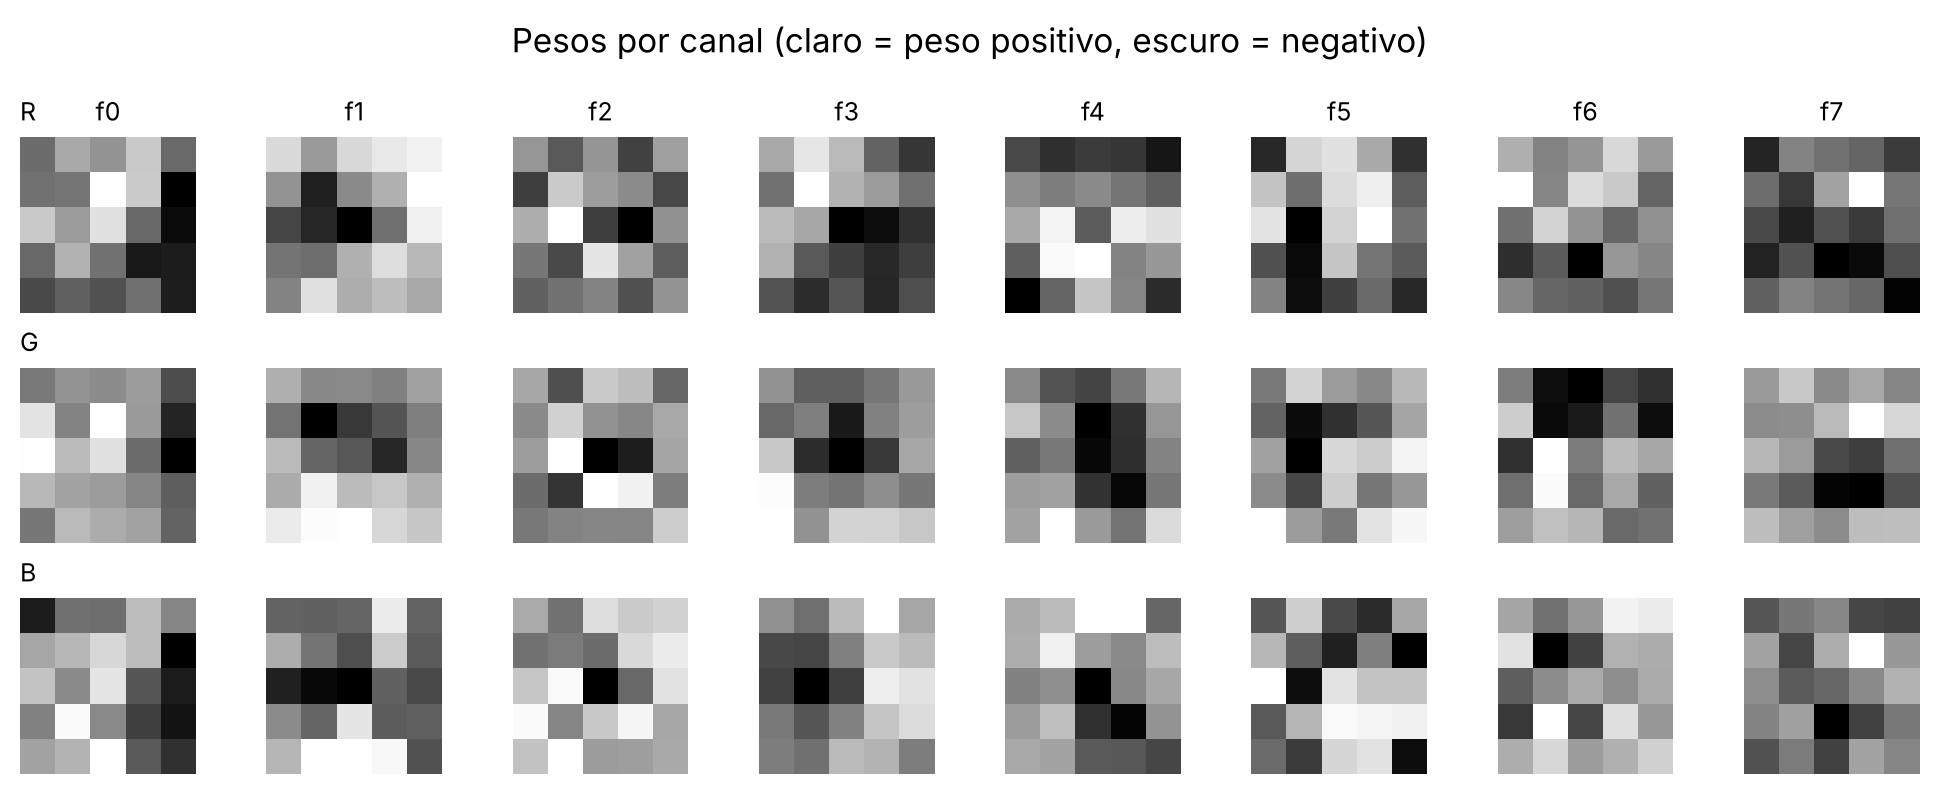

In [14]:
# Visualização complementar: cada canal (R, G, B) de alguns filtros em escala de cinza + resposta a uma imagem
fig, axes = plt.subplots(3, 8, figsize=(10, 4))
for j in range(8):
    for c, nome in enumerate("RGB"):
        axes[c, j].imshow(W[j, c].numpy(), cmap="gray"); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(nome, loc="left", fontsize=9)
    axes[0, j].set_title(f"f{j}", fontsize=9)
plt.suptitle("Pesos por canal (claro = peso positivo, escuro = negativo)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4a_filtros_por_canal.png", dpi=120); plt.show()

### Descrição qualitativa dos filtros
Os filtros desta rede **não são tão "limpos"** quanto os famosos filtros do AlexNet (bordas de Gabor perfeitas). O que se observa:
1. **Filtros dominados por uma cor**, ou seja, detectores de cor/região: verde (f16), azul/ciano (f11), magenta/roxo (f4, f5) e vermelho (f12). Respondem a grandes áreas daquela cor (vegetação, céu/mar, objetos vermelhos).
2. **Filtros de oposição de cor e centro-periferia:** centro de uma cor e vizinhança de outra (f13: centro vermelho-alaranjado contra azul/verde; f10: lado avermelhado contra centro ciano).
3. **Transições claro/escuro com uma direção preferida** (ex.: f20, com metade superior escura e inferior alaranjada; f28 e f30, mais escuros de um lado): são detectores de **borda orientada combinados com cor**.
4. Uma componente de **ruído de alta frequência** em quase todos.

**Por que eles são ruidosos?** (i) A conv1 é seguida de **BatchNorm**: a escala do filtro deixa de importar, e o weight decay não "alisa" os pesos. (ii) As imagens têm só 32×32, então o detalhe útil por patch 5×5 é pequeno. (iii) A conv1 se estabiliza cedo (na época 10 já está quase na forma final) e guarda boa parte da **inicialização aleatória** até o fim: o item 4(d) mede isso. (iv) Redes com 6 convoluções distribuem o trabalho: a conv1 não precisa ser um banco de Gabor perfeito, porque as camadas seguintes corrigem.

**O teste decisivo é funcional:** o que esses filtros *fazem* com uma imagem? A célula abaixo mostra a saída da conv1 (após BN + ReLU). Apesar da aparência ruidosa, os mapas revelam claramente **detectores de borda em direções diferentes** e **detectores de regiões de cor**.

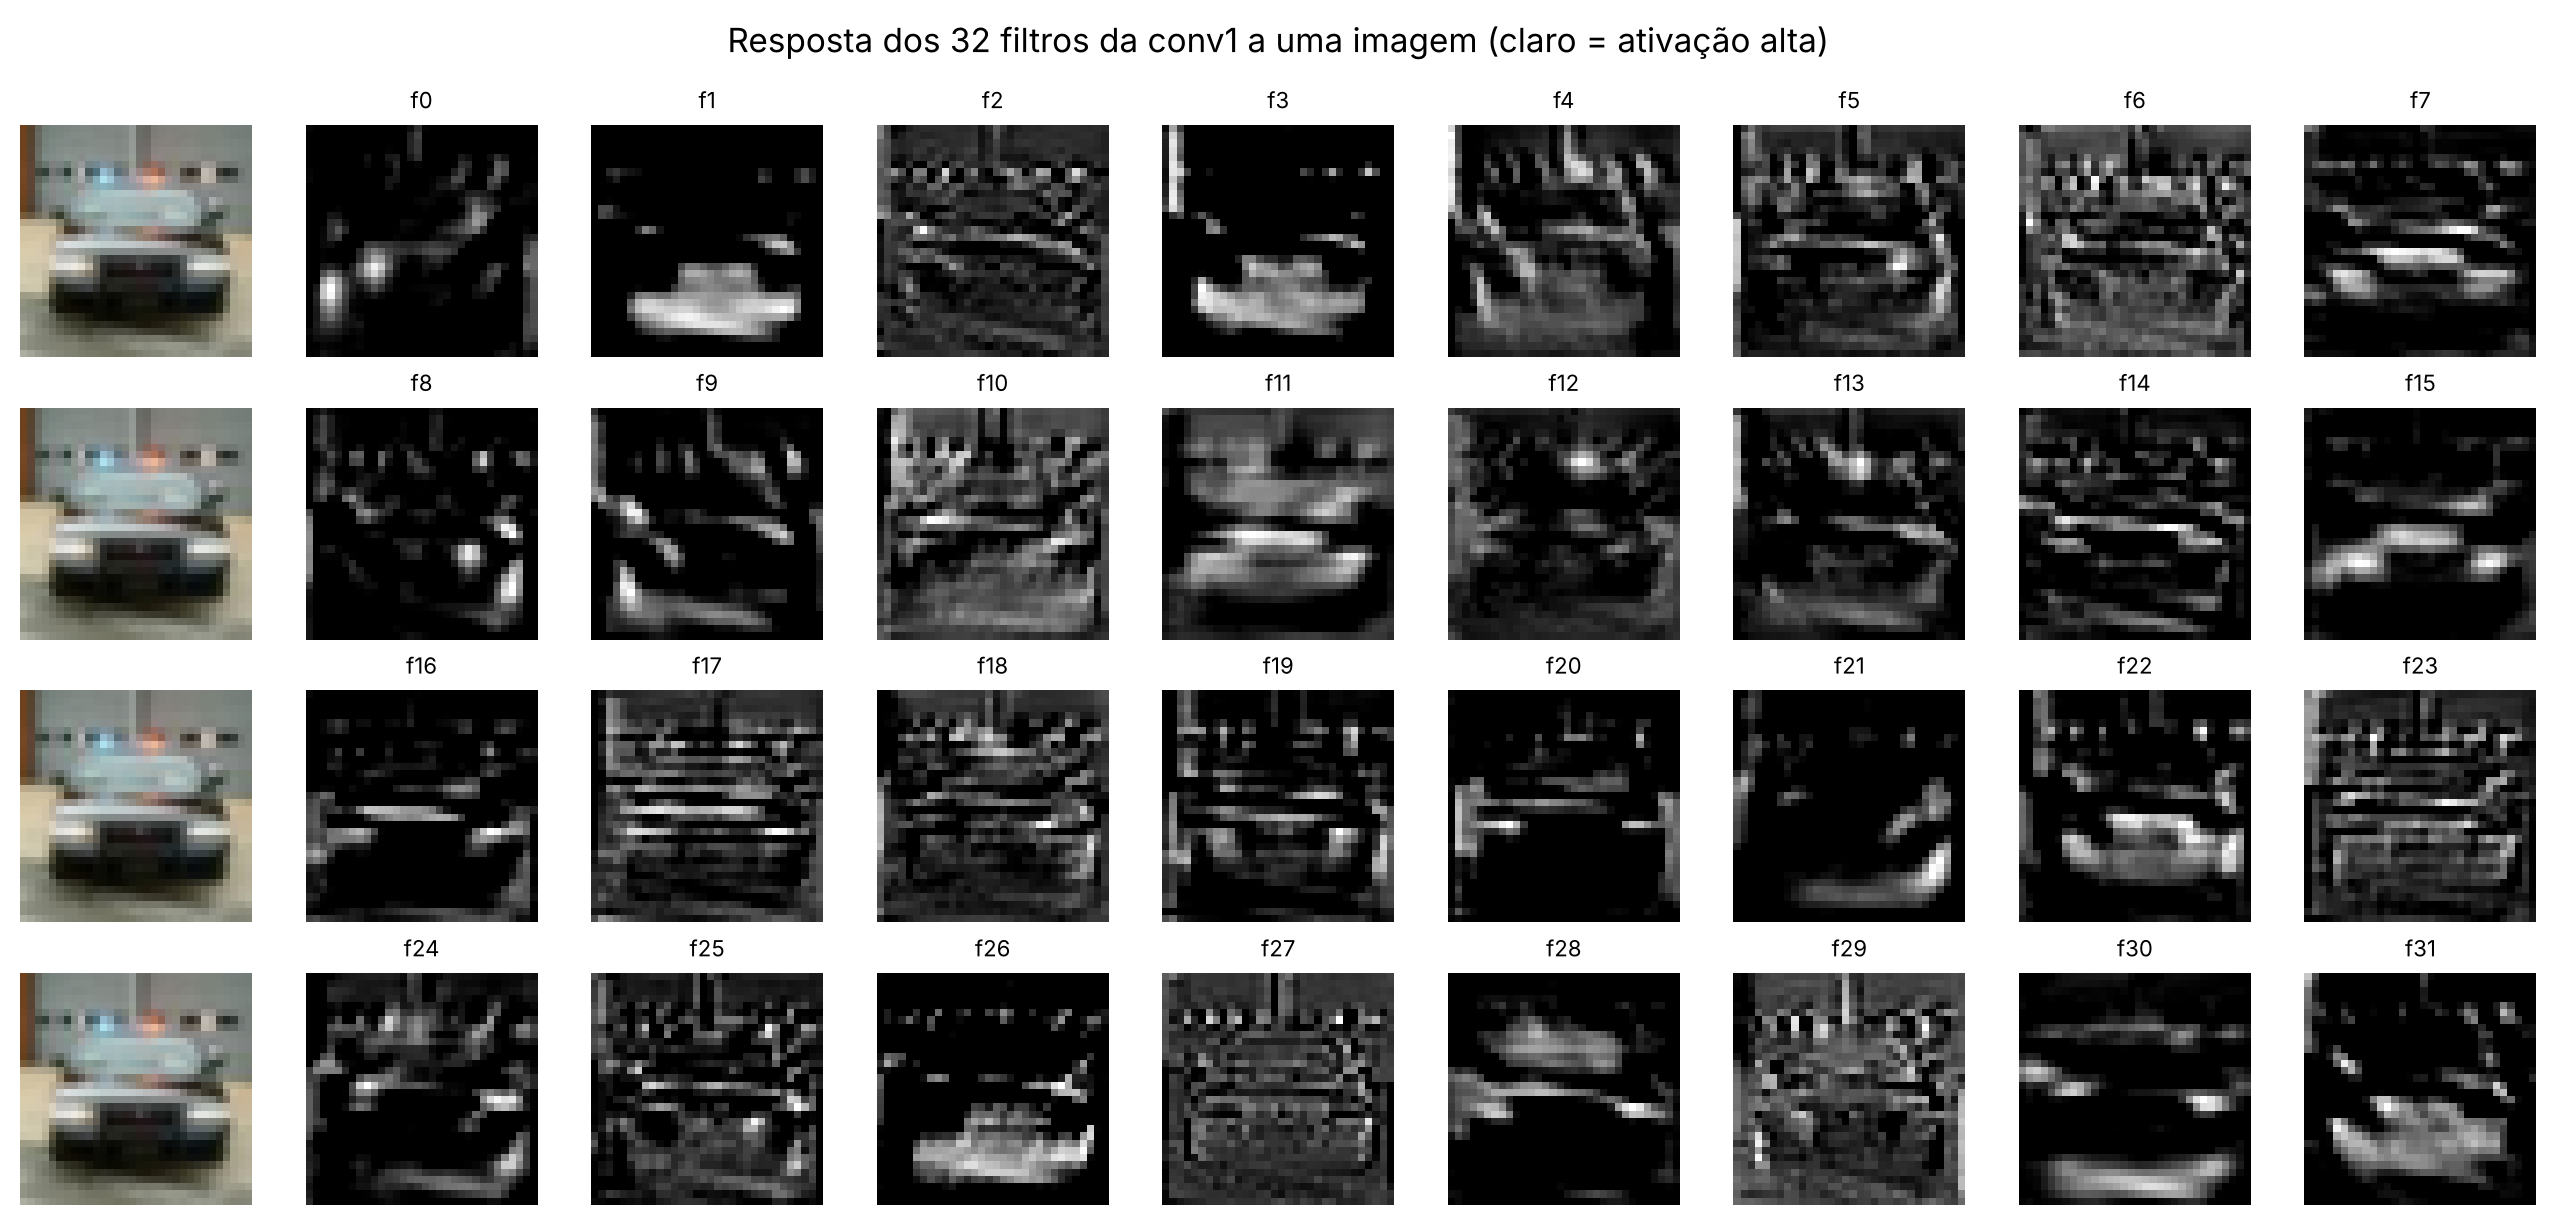

In [15]:
idx_demo = int(np.where((yte.numpy() == 1) & (pred_cnn.numpy() == 1))[0][3])   # um automóvel bem classificado
cnn.eval()
with torch.no_grad():
    r1 = cnn.conv1(Xte_n[idx_demo:idx_demo + 1].to(DEVICE))[0].cpu()        # (32, 32, 32): resposta dos 32 filtros
fig, axes = plt.subplots(4, 9, figsize=(13, 6.2))
img_demo = Xte_u8[idx_demo].permute(1, 2, 0).numpy()
for r in range(4):
    axes[r, 0].imshow(img_demo); axes[r, 0].axis("off")
    for k in range(8):
        f_ = r * 8 + k; axes[r, k + 1].imshow(r1[f_].numpy(), cmap="gray"); axes[r, k + 1].set_title(f"f{f_}", fontsize=8); axes[r, k + 1].axis("off")
plt.suptitle("Resposta dos 32 filtros da conv1 a uma imagem (claro = ativação alta)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4a_respostas_conv1.png", dpi=120); plt.show()

**Leitura:** cada filtro "vê" a mesma imagem de um jeito. Alguns acendem só nos **contornos** com certa orientação (horizontais, verticais ou diagonais), outros nas **áreas claras/escuras** ou de uma cor específica (carroceria, vidros, fundo), e alguns funcionam como **negativo** da imagem. Juntos, formam uma decomposição da imagem em bordas e regiões de cor, que é exatamente a matéria-prima de que as camadas seguintes precisam.

## 4(b) Mapas de ativação de uma camada intermediária
Escolhemos a saída do **bloco 2** (após as convs de 64 filtros, antes do pooling: resolução 16×16). É uma camada intermediária: já combina bordas em texturas/partes, mas ainda preserva a posição espacial.

Usamos **forward hooks** do PyTorch: uma função "gancho" que captura a saída de uma camada durante o forward, sem alterar o modelo.

Para cada imagem mostramos:
- a imagem original;
- os **8 mapas de ativação mais fortes** (canais com maior ativação média) — cada mapa mostra *onde* aquele filtro respondeu;
- a **média de todos os canais** sobreposta à imagem, para ver as regiões que mais ativaram a camada;
- **Grad-CAM** (gradiente da classe predita em relação aos mapas do bloco 3) — indica quais regiões mais **contribuíram para a decisão** da classe, não apenas onde houve ativação.

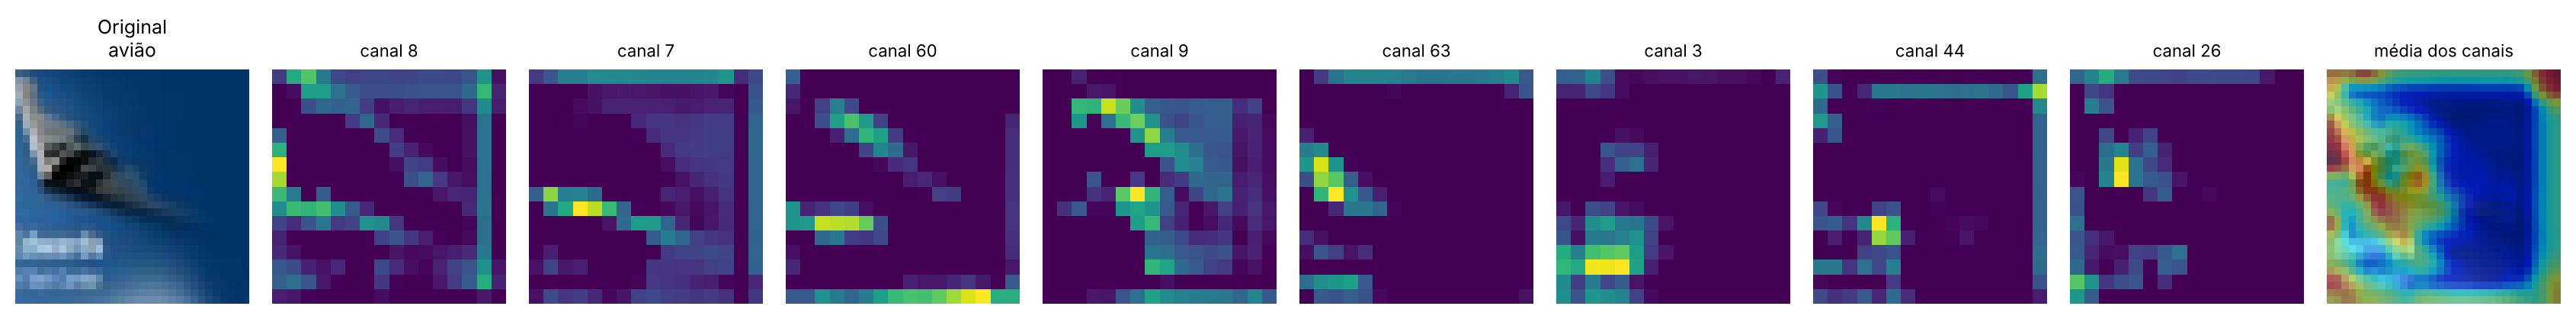

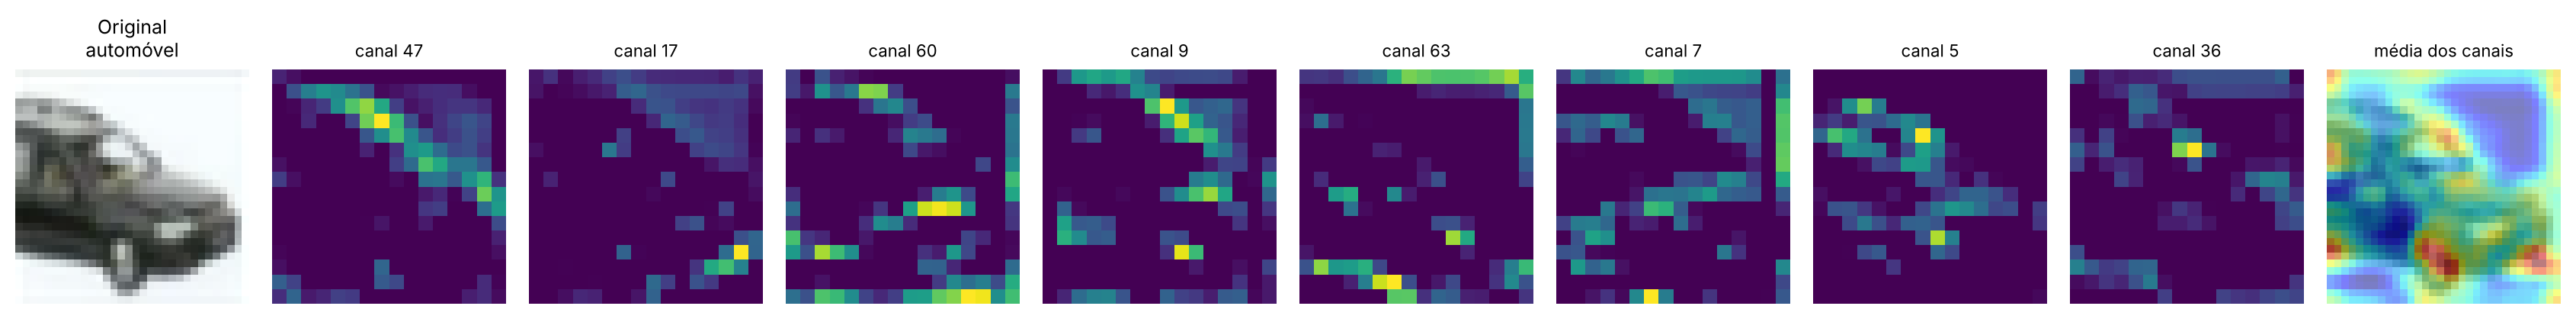

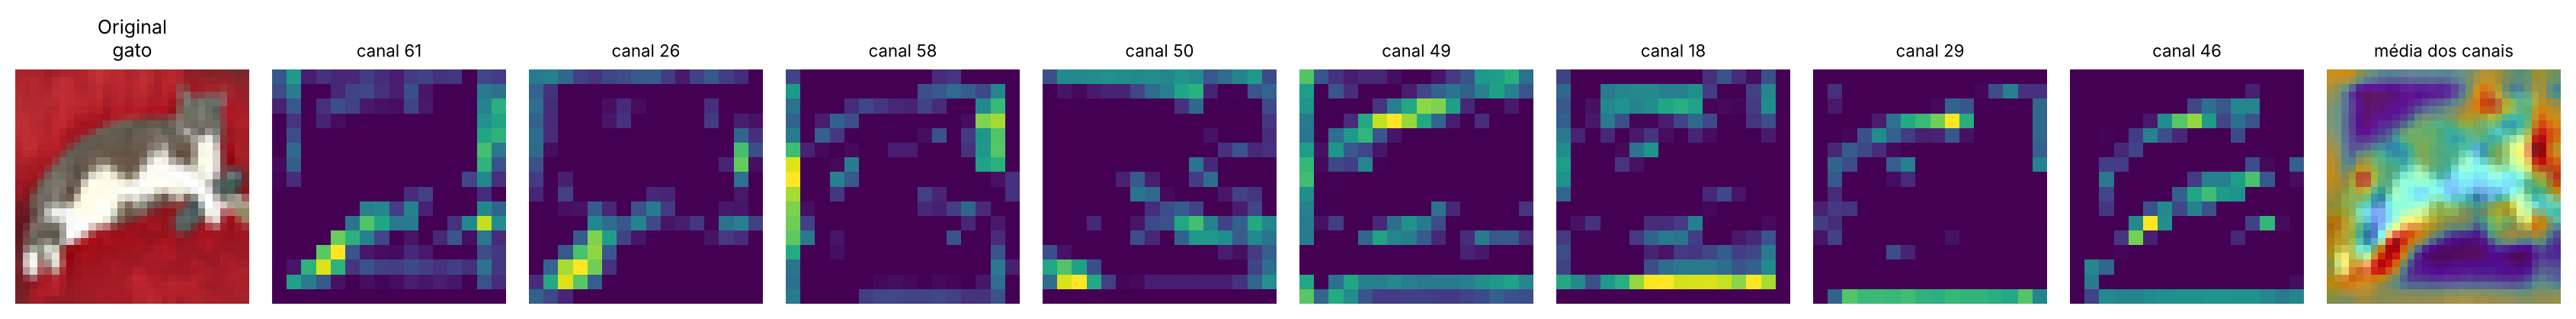

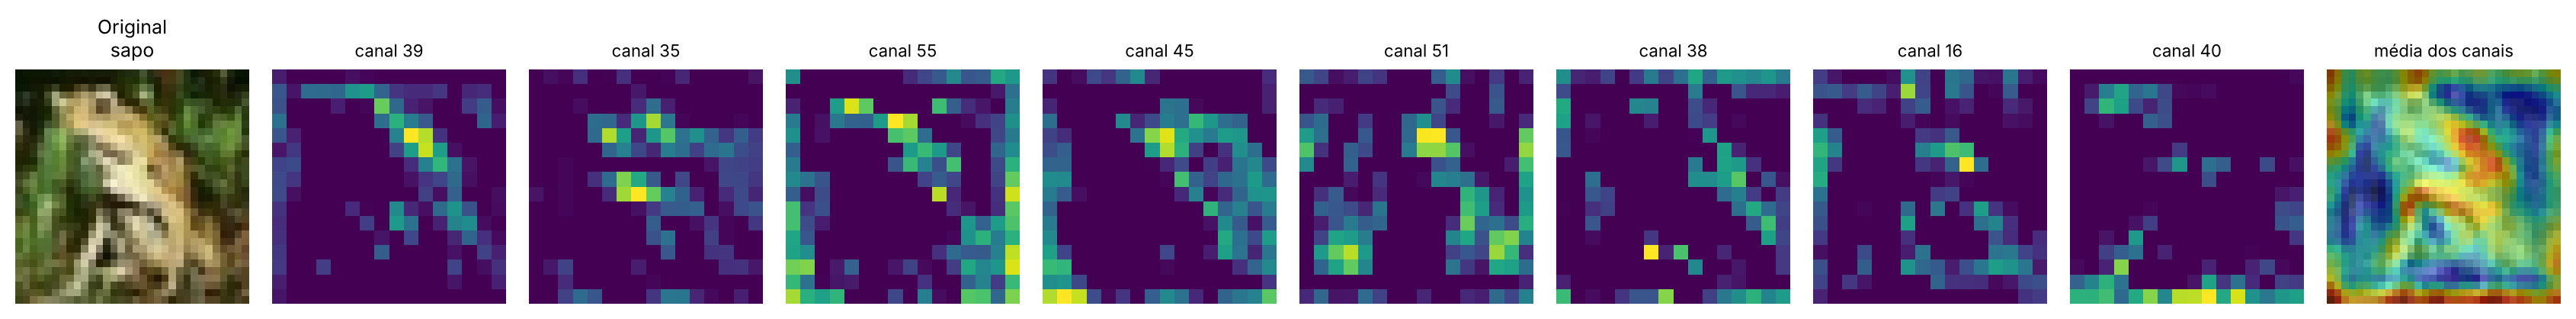

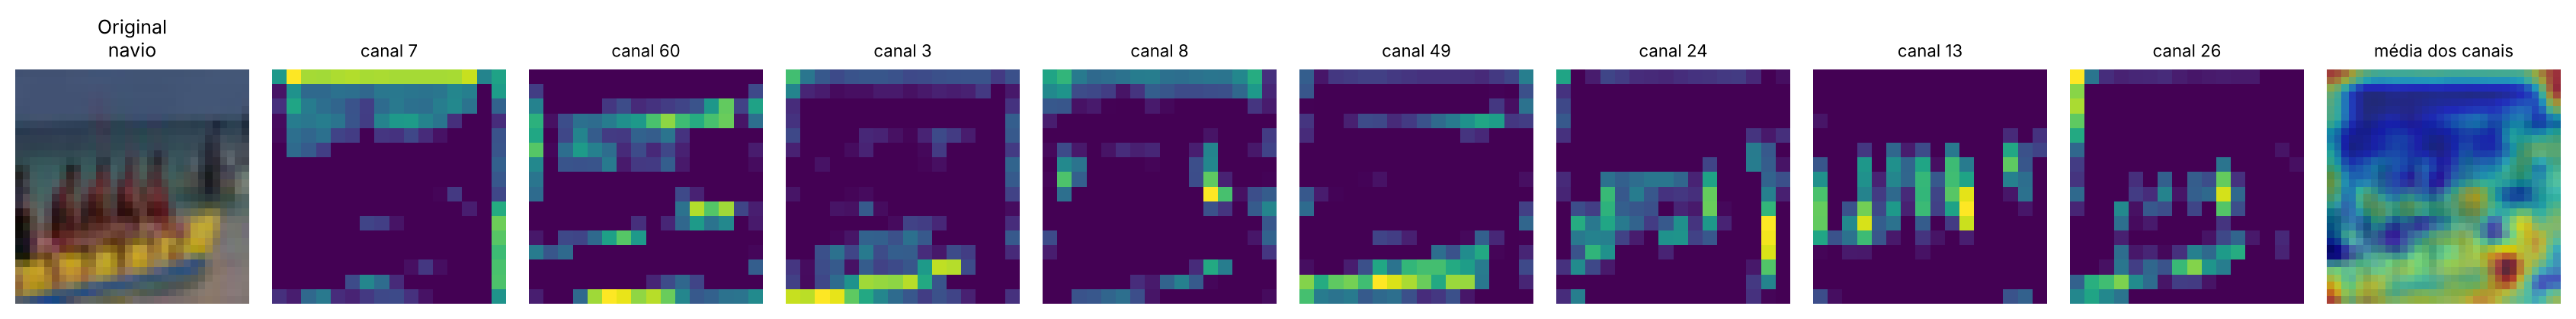

In [16]:
acts = {}
def hook(name):
    def fn(module, inp, out): acts[name] = out.detach()
    return fn
h = cnn.block2[1].register_forward_hook(hook("block2"))   # 2ª conv do bloco 2 (64×16×16)

def denorm(x): return (x * STD[0] + MEAN[0]).clamp(0, 1)

rng = np.random.RandomState(7)
sel = [int(rng.choice(np.where((yte.numpy() == c) & (pred_cnn.numpy() == c))[0])) for c in [0, 1, 3, 6, 8]]  # avião, automóvel, gato, sapo, navio
cnn.eval()
with torch.no_grad():
    _ = cnn(Xte_n[sel].to(DEVICE))
A = acts["block2"].cpu()   # (5, 64, 16, 16)
h.remove()

for n, idx in enumerate(sel):
    a = A[n]; top = a.mean((1, 2)).argsort(descending=True)[:8]
    fig, axes = plt.subplots(1, 10, figsize=(17, 2.2))
    img = denorm(Xte_n[idx]).permute(1, 2, 0).numpy()
    axes[0].imshow(img); axes[0].set_title(f"Original\n{CLASSES[yte[idx]]}", fontsize=9)
    for k, ch in enumerate(top):
        axes[k + 1].imshow(a[ch].numpy(), cmap="viridis"); axes[k + 1].set_title(f"canal {ch.item()}", fontsize=8)
    m = a.mean(0); m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    m_up = F.interpolate(m[None, None], size=32, mode="bilinear", align_corners=False)[0, 0].numpy()
    axes[9].imshow(img); axes[9].imshow(m_up, cmap="jet", alpha=0.5); axes[9].set_title("média dos canais", fontsize=8)
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"q4b_ativacoes_{n + 1}_{CLASSES[yte[idx]]}.png", dpi=120); plt.show()

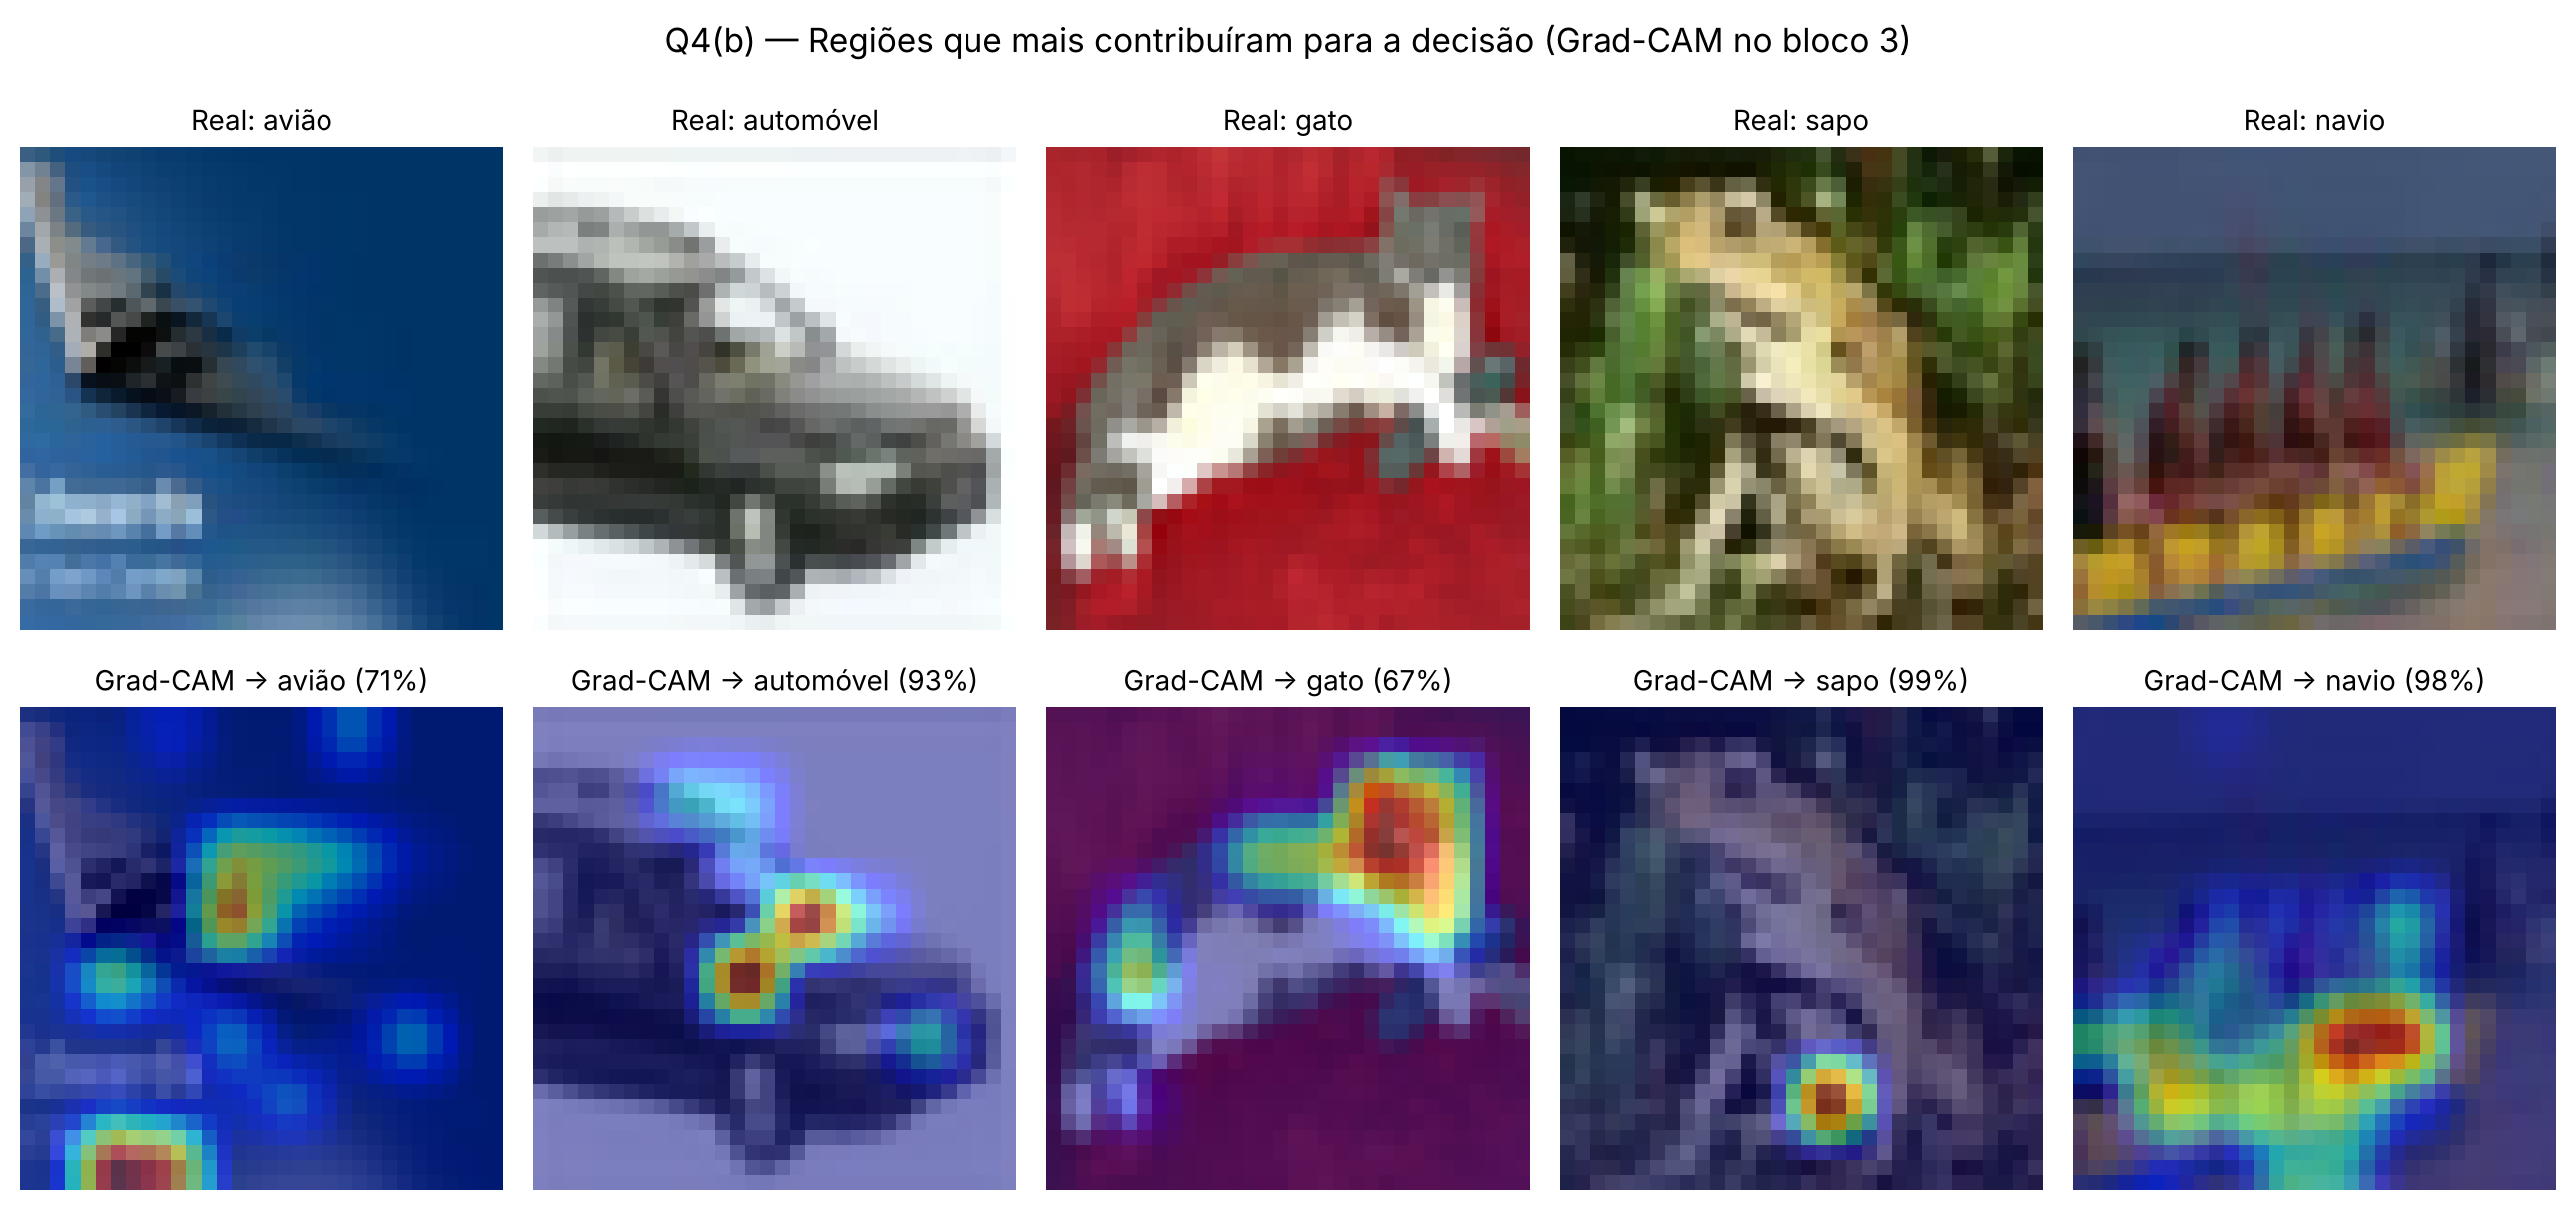

In [17]:
def grad_cam(model, x, target_layer):
    """Grad-CAM: pondera cada mapa de ativação pela média do gradiente da classe predita."""
    store = {}
    def fwd(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))   # captura o gradiente desse tensor
    fh = target_layer.register_forward_hook(fwd)
    model.eval(); x = x.to(DEVICE)
    out = model(x); cls = out.argmax(1)
    model.zero_grad(); out.gather(1, cls[:, None]).sum().backward()
    fh.remove()
    w = store["g"].mean((2, 3), keepdim=True)                  # importância de cada canal
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))        # combinação ponderada
    cam = F.interpolate(cam, size=32, mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin((1, 2), keepdim=True); cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu(), cls.cpu(), out.softmax(1).detach().cpu()

cams, cls, pr = grad_cam(cnn, Xte_n[sel], cnn.block3[1])
fig, axes = plt.subplots(2, 5, figsize=(13, 6.4))
for n, idx in enumerate(sel):
    img = denorm(Xte_n[idx]).permute(1, 2, 0).numpy()
    axes[0, n].imshow(img); axes[0, n].set_title(f"Real: {CLASSES[yte[idx]]}", fontsize=10)
    axes[1, n].imshow(img); axes[1, n].imshow(cams[n].numpy(), cmap="jet", alpha=0.5)
    axes[1, n].set_title(f"Grad-CAM → {CLASSES[cls[n]]} ({pr[n, cls[n]]:.0%})", fontsize=10)
    for ax in axes[:, n]: ax.axis("off")
plt.suptitle("Q4(b) — Regiões que mais contribuíram para a decisão (Grad-CAM no bloco 3)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4b_gradcam.png", dpi=130); plt.show()

### Análise qualitativa das ativações
- **Canais especialistas em contorno:** a maioria dos 8 canais mais fortes acende ao longo de **contornos com orientação específica**. No avião e no automóvel aparecem os canais diagonais, que seguem a fuselagem e o capô/para-brisa; no gato, vários canais traçam a **curva do dorso**; no navio, o canal 13 responde às **estruturas verticais** (pessoas/mastros sobre o barco). São bordas da conv1 combinadas em formas maiores.
- **Texturas:** no sapo, os mapas ficam fragmentados e espalhados pelo corpo e pela vegetação, ou seja, a camada responde à **textura** rugosa e ao fundo, mais do que a um contorno único.
- **Artefato de borda:** vários canais acendem nas **margens da imagem**. É efeito do *zero-padding*: a transição entre a imagem e os zeros do padding parece uma borda. Por isso a "média dos canais" às vezes destaca cantos e fundo (no gato, o fundo vermelho também ativa bastante).
- **Ativação ≠ importância.** A média das ativações mostra *onde há estrutura*, não o que decidiu a classe. O **Grad-CAM** responde a essa segunda pergunta:
  - **gato:** foco na **cabeça/orelhas**, a parte mais discriminativa (é o que separa gato de cachorro);
  - **automóvel:** a região do **para-brisa/coluna dianteira** (onde capô, vidro e teto se encontram) e, mais fraco, o **farol**; as rodas quase não aparecem — a rede usa a silhueta característica do carro;
  - **navio:** o **casco** amarelo sobre a água;
  - **sapo:** uma região pequena na parte de baixo (pata/corpo), com 99% de confiança. A textura sozinha já bastou;
  - **avião:** além da fuselagem, o Grad-CAM acende sobre o **texto (marca d'água) no canto inferior esquerdo**. Esse é um **atalho espúrio**: no CIFAR-10, fotos de avião costumam vir de catálogos com legendas, e a rede aprendeu a usar isso como pista. É o tipo de viés que as técnicas de interpretabilidade servem para revelar.
- A resolução é baixa (16×16 no bloco 2, 8×8 no bloco 3), então os mapas são grosseiros; em redes maiores e imagens maiores a localização fica mais nítida.

## 4(c) Exemplos corretos e incorretos, com probabilidade
A probabilidade associada é a saída do **softmax** para a classe predita. Também mostramos a probabilidade dada à **classe verdadeira** nos erros — isso revela se o erro foi "por pouco" ou se a rede estava confiante e errada.

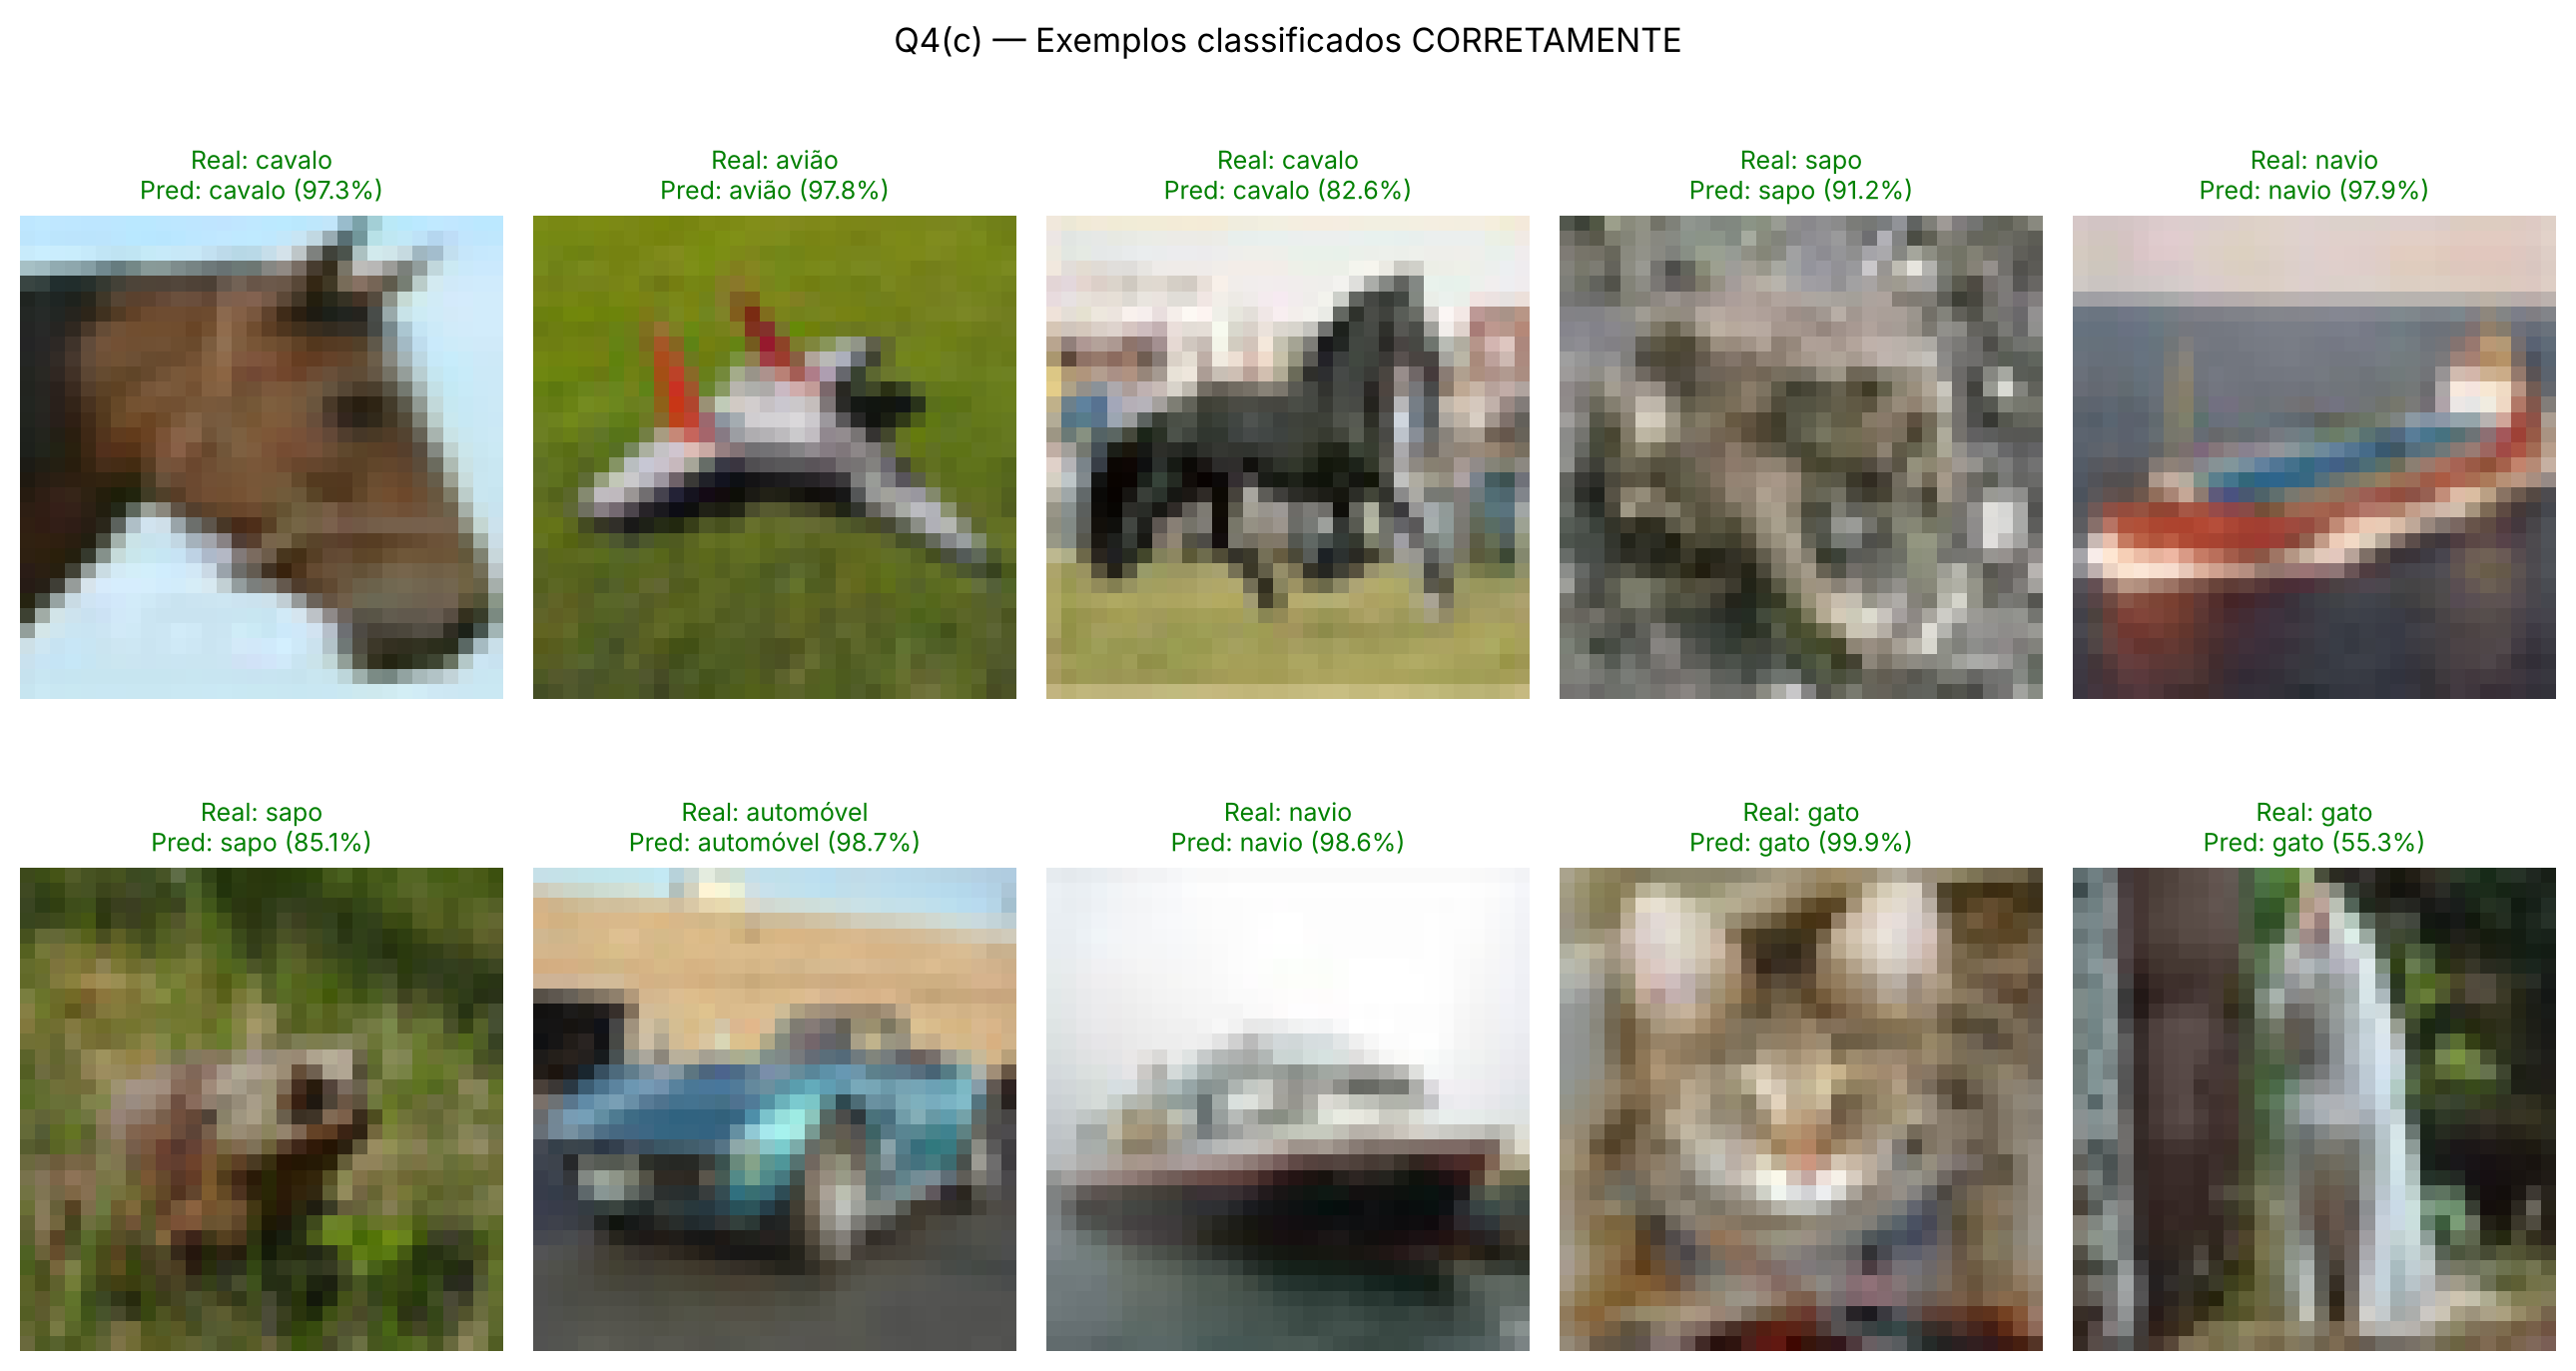

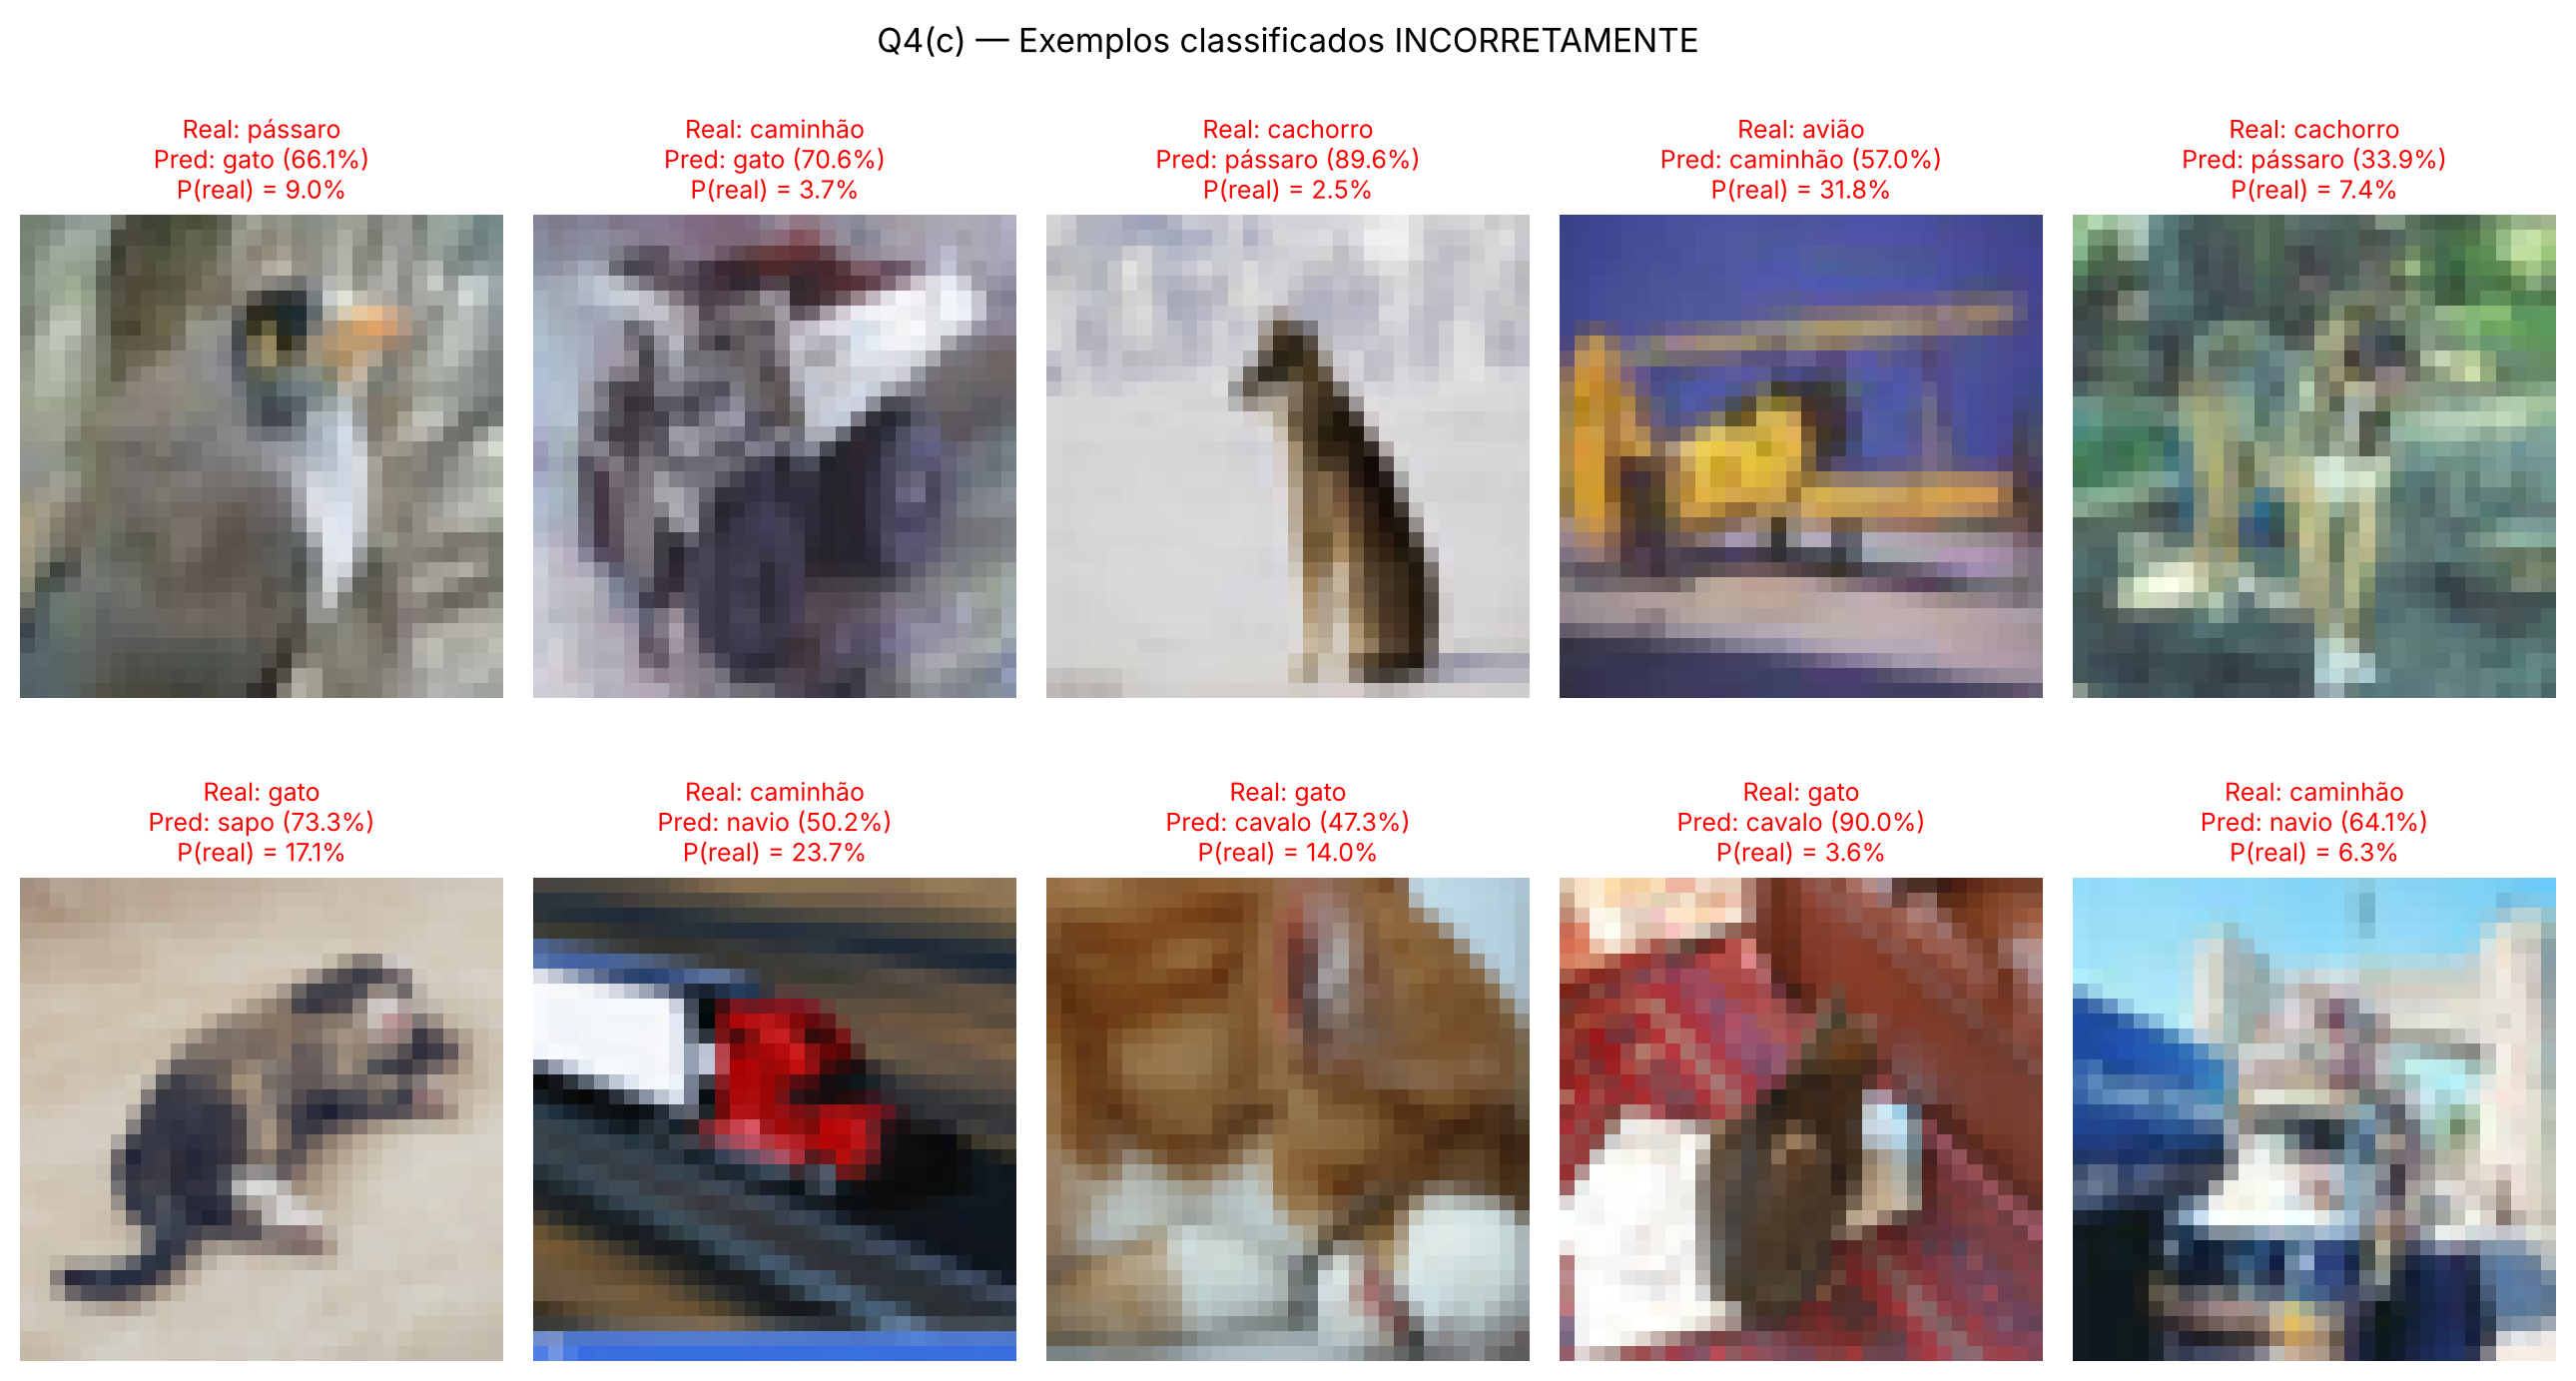

In [18]:
probs = prob_cnn; conf = probs.max(1).values
correct = np.where(pred_cnn.numpy() == yte.numpy())[0]
wrong = np.where(pred_cnn.numpy() != yte.numpy())[0]
rng = np.random.RandomState(SEED)
ex_ok = rng.choice(correct, 10, replace=False)
ex_err = rng.choice(wrong, 10, replace=False)

def show_examples(indices, title, fname):
    fig, axes = plt.subplots(2, 5, figsize=(13, 7.6))
    for ax, i in zip(axes.flat, indices):
        ax.imshow(Xte_u8[i].permute(1, 2, 0).numpy()); ax.axis("off")
        t, p = yte[i].item(), pred_cnn[i].item()
        cor = "green" if t == p else "red"
        ax.set_title(f"Real: {CLASSES[t]}\nPred: {CLASSES[p]} ({probs[i, p]:.1%})"
                     + ("" if t == p else f"\nP(real) = {probs[i, t]:.1%}"), fontsize=9, color=cor)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=130); plt.show()

show_examples(ex_ok, "Q4(c) — Exemplos classificados CORRETAMENTE", "q4c_corretos.png")
show_examples(ex_err, "Q4(c) — Exemplos classificados INCORRETAMENTE", "q4c_incorretos.png")

,índice,real,predita,P(predita),P(real),top-3
0,7395,pássaro,gato,66.1%,9.0%,"gato 66%, cachorro 13%, pássaro 9%"
1,5151,caminhão,gato,70.6%,3.7%,"gato 71%, cachorro 6%, sapo 5%"
2,6257,cachorro,pássaro,89.6%,2.5%,"pássaro 90%, gato 3%, cachorro 3%"
3,6812,avião,caminhão,57.0%,31.8%,"caminhão 57%, avião 32%, navio 6%"
4,9369,cachorro,pássaro,33.9%,7.4%,"pássaro 34%, navio 25%, cervo 12%"
5,1129,gato,sapo,73.3%,17.1%,"sapo 73%, gato 17%, cachorro 6%"
6,2059,caminhão,navio,50.2%,23.7%,"navio 50%, caminhão 24%, automóvel 6%"
7,6647,gato,cavalo,47.3%,14.0%,"cavalo 47%, cervo 16%, cachorro 16%"
8,898,gato,cavalo,90.0%,3.6%,"cavalo 90%, cachorro 4%, gato 4%"
9,2271,caminhão,navio,64.1%,6.3%,"navio 64%, avião 23%, caminhão 6%"


Confiança média nos ACERTOS: 88.3% | nos ERROS: 57.6%


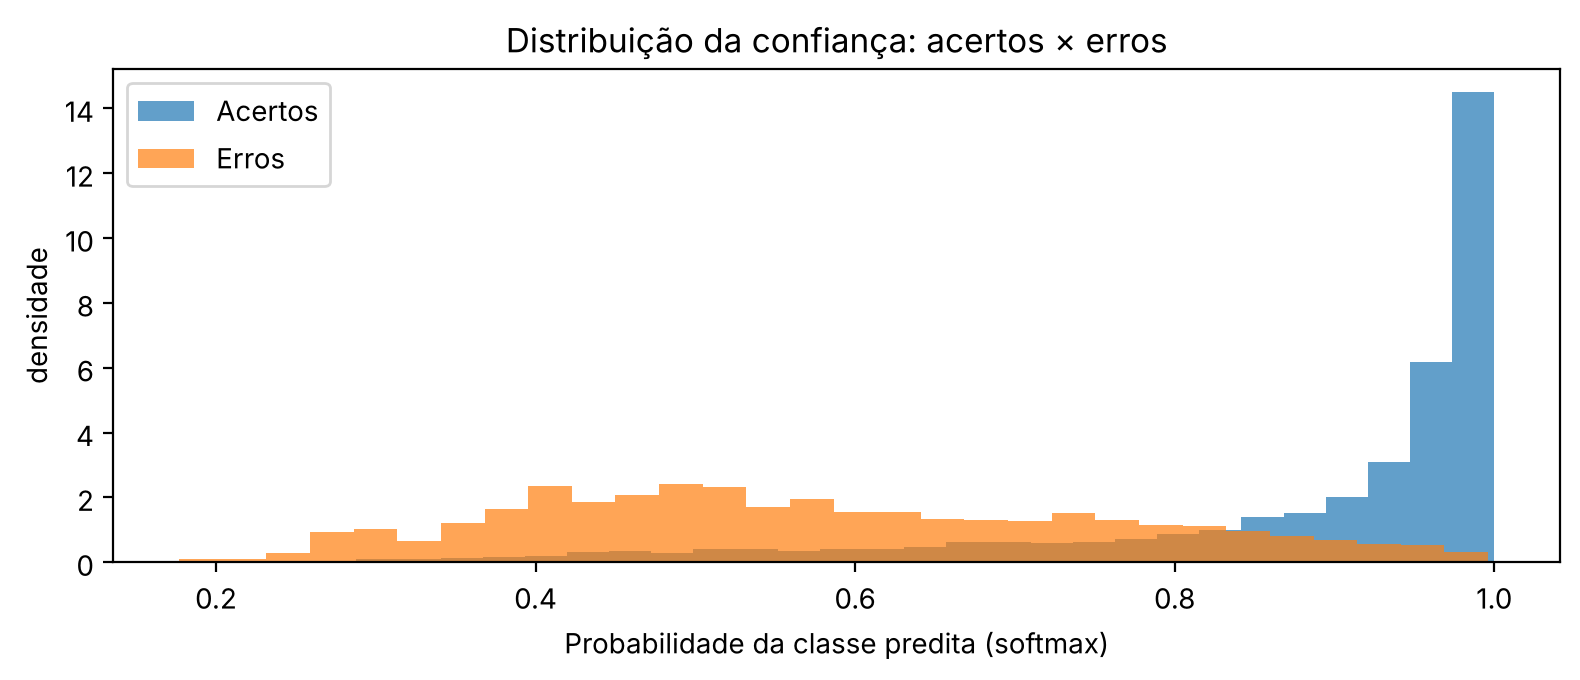

In [19]:
# Top-3 probabilidades de alguns erros + erros mais confiantes
tab = []
for i in ex_err:
    top3 = probs[i].topk(3)
    tab.append({"índice": int(i), "real": CLASSES[yte[i]], "predita": CLASSES[pred_cnn[i]],
                "P(predita)": f"{probs[i, pred_cnn[i]]:.1%}", "P(real)": f"{probs[i, yte[i]]:.1%}",
                "top-3": ", ".join(f"{CLASSES[c]} {v:.0%}" for v, c in zip(top3.values, top3.indices))})
display(pd.DataFrame(tab))

print(f"Confiança média nos ACERTOS: {conf[correct].mean():.1%} | nos ERROS: {conf[wrong].mean():.1%}")
plt.figure(figsize=(8, 3.5))
plt.hist(conf[correct].numpy(), bins=30, alpha=.7, label="Acertos", density=True)
plt.hist(conf[wrong].numpy(), bins=30, alpha=.7, label="Erros", density=True)
plt.xlabel("Probabilidade da classe predita (softmax)"); plt.ylabel("densidade"); plt.legend()
plt.title("Distribuição da confiança: acertos × erros"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4c_confianca.png", dpi=120); plt.show()

### Discussão (Q4c)
- **Acertos:** confiança média de **88%**. O teto fica um pouco abaixo de 100% de propósito: o *label smoothing* (0,05) impede a rede de ficar 100% certa, o que melhora a calibração.
- **Erros:** confiança média de só **58%**. Em 7 dos 10 erros mostrados, a **classe verdadeira está no top-3**, ou seja, a rede "hesitou" entre classes parecidas (pássaro → gato 66% com pássaro em 3º; avião → caminhão 57% × avião 32%; caminhão → navio 50% × caminhão 24%).
- Também há **erros confiantes**: um gato chamado de cavalo com 90% e um cachorro chamado de pássaro com 90%. São imagens com pose atípica, objeto pequeno ou recortado, ou fundo enganoso. Coincidem com a dependência de contexto que vimos nos mapas de ativação.
- O histograma mostra distribuições de confiança bem separadas. Na prática, a probabilidade do softmax pode servir como **critério de rejeição**: abaixo de um limiar (ex.: 60%), a imagem é encaminhada para revisão humana, e a maioria dos erros é capturada com pouca perda de acertos.


---
## 4(d) Evolução das representações ao longo do treinamento
O enunciado pede para investigar as representações aprendidas pela CNN **ao longo do treinamento**. Os itens (a)–(c) analisam a CNN **final**; aqui acompanhamos como essas representações **surgem**.

**Procedimento:**
1. Retreinamos a **mesma CNN da Q3** (mesma arquitetura, hiperparâmetros, augmentation, label smoothing e agendamento OneCycle de 25 épocas), salvando **checkpoints nas épocas 0 (inicialização aleatória), 1, 2, 5, 10 e 25** em `modelos/cnn_checkpoints.pt`. Se esse arquivo existir, os checkpoints são carregados em vez de retreinar (para forçar o treino: `RETRAIN=1`).
2. Para cada checkpoint comparamos: acurácia, **filtros da conv1**, quanto cada camada ainda muda, **mapas de ativação** do bloco 2 e **Grad-CAM** nas mesmas 5 imagens da Q4(b).

> Observação: o treino em GPU não é bit-a-bit determinístico e o estado do gerador aleatório difere do treino da seção 5 (lá a MLP foi treinada antes), então este retreino é uma **nova execução** da mesma receita: os números finais ficam próximos, mas não idênticos, aos da CNN da Q3.

### Retreino com checkpoints
Mesma receita da Q3: AdamW (lr máx. 3e-3, weight decay 5e-4), OneCycle, lotes de 128, augmentation (crop + flip), label smoothing 0,05, 25 épocas.


In [20]:
# Usa CNN, augment, evaluate, Xtr_n/ytr e Xva_n/yva definidos nas seções anteriores.
CKPTS = [0, 1, 2, 5, 10, 25]
EPOCHS, BS, LR = 25, 128, 3e-3
ck_path = MODEL_DIR / "cnn_checkpoints.pt"

if ck_path.exists() and os.environ.get("RETRAIN", "0") != "1":
    saved = torch.load(ck_path, map_location="cpu")
    snaps, hist_ck = saved["snaps"], saved["hist"]
    print("Checkpoints carregados de", ck_path)
else:
    torch.manual_seed(SEED)
    model_ck = CNN().to(DEVICE)
    snaps = {0: copy.deepcopy({k: v.cpu() for k, v in model_ck.state_dict().items()})}
    opt_ck = torch.optim.AdamW(model_ck.parameters(), lr=LR, weight_decay=5e-4)
    sched_ck = torch.optim.lr_scheduler.OneCycleLR(opt_ck, max_lr=LR, total_steps=EPOCHS * ((len(ytr) + BS - 1) // BS))
    hist_ck = {"train_loss": [], "val_acc": []}
    for ep in range(1, EPOCHS + 1):
        model_ck.train(); t0 = time.time(); tl = 0.0; pp = torch.randperm(len(ytr))
        for k in range(0, len(ytr), BS):
            idx = pp[k:k + BS]
            xb, yb = augment(Xtr_n[idx]).to(DEVICE), ytr[idx].to(DEVICE)
            out = model_ck(xb); loss = F.cross_entropy(out, yb, label_smoothing=0.05)
            opt_ck.zero_grad(); loss.backward(); opt_ck.step(); sched_ck.step()
            tl += loss.item() * len(idx)
        _, va, _, _ = evaluate(model_ck, Xva_n, yva)
        hist_ck["train_loss"].append(tl / len(ytr)); hist_ck["val_acc"].append(va)
        if ep in CKPTS:
            snaps[ep] = copy.deepcopy({k: v.cpu() for k, v in model_ck.state_dict().items()})
        print(f"época {ep:02d} | perda treino {tl / len(ytr):.4f} | acc val {va:.3f} | {time.time() - t0:.0f}s" + ("  ← checkpoint" if ep in CKPTS else ""))
    torch.save({"snaps": snaps, "hist": hist_ck}, ck_path)

def load_ckpt(ep):
    m = CNN().to(DEVICE); m.load_state_dict(snaps[ep]); m.eval(); return m

época 01 | perda treino 1.7942 | acc val 0.550 | 5s  ← checkpoint


época 02 | perda treino 1.4854 | acc val 0.638 | 5s  ← checkpoint


época 03 | perda treino 1.3112 | acc val 0.662 | 5s


época 04 | perda treino 1.1983 | acc val 0.724 | 5s


época 05 | perda treino 1.1116 | acc val 0.736 | 5s  ← checkpoint


época 06 | perda treino 1.0511 | acc val 0.764 | 5s


... (15 outputs left out)

época 22 | perda treino 0.6324 | acc val 0.897 | 5s


época 23 | perda treino 0.6275 | acc val 0.893 | 5s


época 24 | perda treino 0.6216 | acc val 0.894 | 5s


época 25 | perda treino 0.6179 | acc val 0.896 | 5s  ← checkpoint


### Desempenho em cada checkpoint


In [21]:
# sel = as mesmas 5 imagens da Q4(b); acc_cnn/prob_cnn = CNN da Q3 (seção 5)
rows = []
for ep in CKPTS:
    m = load_ckpt(ep)
    _, a_va, _, _ = evaluate(m, Xva_n, yva); _, a_te, _, pr = evaluate(m, Xte_n, yte)
    rows.append({"época": ep, "acc validação": a_va, "acc teste": a_te,
                 "P(classe real) média nas 5 imagens": pr[sel, yte[sel]].mean().item()})
rows.append({"época": "CNN da Q3 (referência)", "acc validação": float("nan"), "acc teste": acc_cnn,
             "P(classe real) média nas 5 imagens": prob_cnn[sel, yte[sel]].mean().item()})
perf = pd.DataFrame(rows).set_index("época")
display(perf.style.format("{:.3f}", na_rep="—"))

,acc validação,acc teste,P(classe real) média nas 5 imagens
época,,,
0,0.096,0.100,0.101
1,0.550,0.539,0.361
2,0.638,0.630,0.418
5,0.736,0.739,0.756
10,0.831,0.823,0.795
25,0.896,0.891,0.864
CNN da Q3 (referência),—,0.888,0.856


**Leitura:** a acurácia sobe rápido no início (10% → 55% já na 1ª época) e depois desacelera. O retreino termina com **89,1% no teste**, praticamente o mesmo resultado da CNN da Q3 (88,9%). A receita é reproduzível e as conclusões abaixo valem para a CNN analisada em (a)–(c). A probabilidade média dada à classe correta nas 5 imagens da Q4(b) sobe de 10% (chute) para 86%.


### Filtros da conv1 ao longo do treino
Cada linha é um checkpoint; as colunas são os **mesmos 8 filtros** (os 8 de maior norma no modelo final), normalizados individualmente para [0, 1], como na Q4(a).

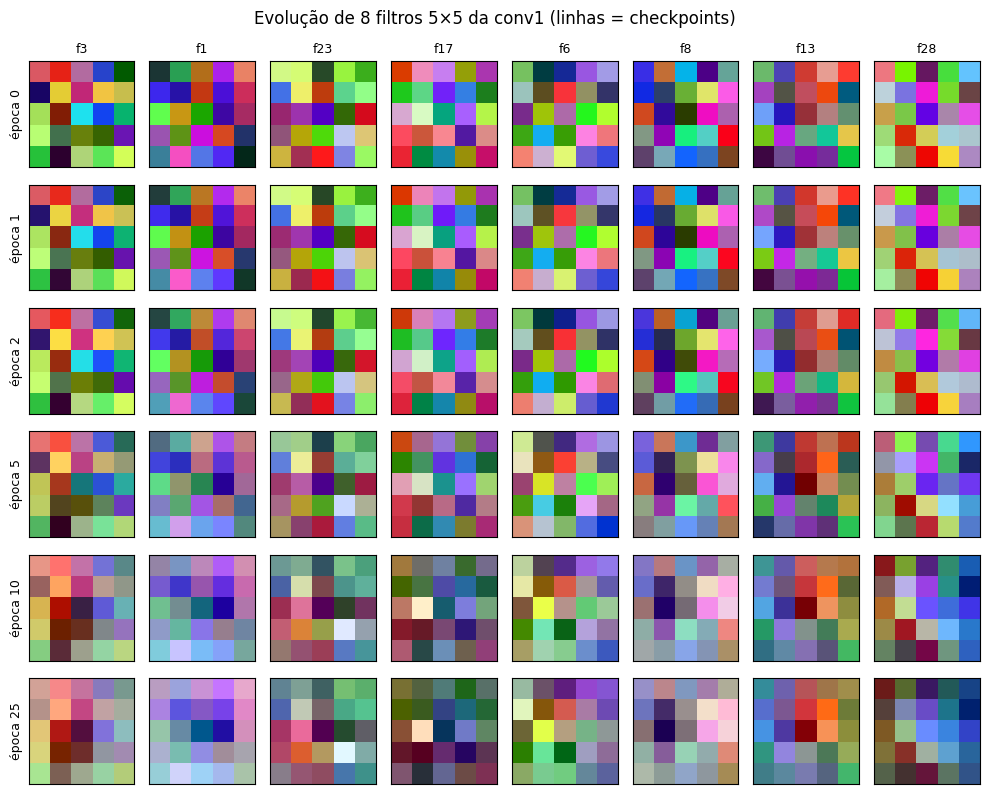

,norma média dos filtros,rugosidade (↓ = mais suave),fração de energia de cor
época,,,
0,0.570,1.316,0.668
1,0.570,1.319,0.671
2,0.574,1.323,0.660
5,0.657,1.301,0.576
10,0.925,1.235,0.474
25,1.191,1.204,0.459


In [22]:
Wck = {ep: snaps[ep]["conv1.0.weight"] for ep in CKPTS}            # (32, 3, 5, 5)
show = Wck[CKPTS[-1]].flatten(1).norm(dim=1).argsort(descending=True)[:8].tolist()
fig, axes = plt.subplots(len(CKPTS), 8, figsize=(10, 1.35 * len(CKPTS)))
for r, ep in enumerate(CKPTS):
    for c, f_ in enumerate(show):
        w = Wck[ep][f_]; w = (w - w.min()) / (w.max() - w.min() + 1e-8)
        axes[r, c].imshow(w.permute(1, 2, 0).numpy(), interpolation="nearest"); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0: axes[r, c].set_title(f"f{f_}", fontsize=9)
    axes[r, 0].set_ylabel(f"época {ep}", fontsize=9)
plt.suptitle("Evolução de 8 filtros 5×5 da conv1 (linhas = checkpoints)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4evo_filtros_conv1.png", dpi=130); plt.show()

# Medidas quantitativas dos filtros
def smoothness(w):
    # razão entre a variação entre pixels vizinhos e a variação total: quanto MENOR, mais suave (menos ruído de alta frequência)
    dx = (w[..., 1:, :] - w[..., :-1, :]).abs().mean(); dy = (w[..., :, 1:] - w[..., :, :-1]).abs().mean()
    return ((dx + dy) / 2 / (w - w.mean()).abs().mean()).item()
def color_energy(w):
    # fração da energia do filtro que NÃO é comum aos 3 canais (0 = filtro cinza; maior = mais seletivo a cor)
    gray = w.mean(1, keepdim=True)
    return ((w - gray) ** 2).sum().item() / (w ** 2).sum().item()
filt = pd.DataFrame({ep: {"norma média dos filtros": Wck[ep].flatten(1).norm(dim=1).mean().item(),
                          "rugosidade (↓ = mais suave)": smoothness(Wck[ep]),
                          "fração de energia de cor": color_energy(Wck[ep])} for ep in CKPTS}).T
filt.index.name = "época"
display(filt.style.format("{:.3f}"))

**Leitura (filtros da conv1):**
- **Épocas 0–2:** os filtros são praticamente **idênticos à inicialização aleatória**: padrões de cor saturados e sem estrutura. Nessa fase, o que muda são as camadas seguintes e as estatísticas do BatchNorm.
- **Época 5 em diante:** as cores ficam **menos saturadas e mais coordenadas**. Aparecem regiões com o mesmo tom (ex.: f1 e f8 tendendo a azul/lilás uniforme, f17 a verde-oliva escuro) e transições claro/escuro, e da época 10 para a 25 a mudança já é pequena.
- **Quantitativamente:**
  - a **norma** dos filtros dobra (0,57 → 1,19), ou seja, a camada aprende a responder mais forte a padrões úteis;
  - a **fração de energia de cor** cai de 0,67 (valor esperado para pesos aleatórios independentes por canal) para 0,46: os filtros passam a responder mais à **luminosidade** (bordas e claro/escuro), embora quase metade da energia continue seletiva a cor;
  - a **rugosidade** cai só ~9% (1,32 → 1,20): eles **não** viram filtros suaves tipo Gabor em 25 épocas.
- A análise seguinte (quanto cada camada ainda muda) mostra o porquê.


### Quanto cada camada ainda muda?
Para cada camada medimos a **similaridade de cosseno** entre os pesos no checkpoint e os pesos **finais** (época 25). Valor 1 = a camada já está na forma final.

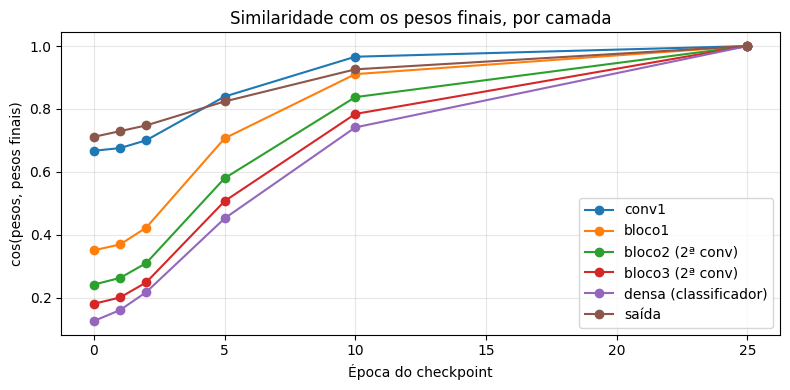

,conv1,bloco1,bloco2 (2ª conv),bloco3 (2ª conv),densa (classificador),saída
época,,,,,,
0,0.667,0.351,0.242,0.181,0.126,0.712
1,0.676,0.369,0.263,0.201,0.161,0.730
2,0.700,0.423,0.310,0.249,0.218,0.748
5,0.840,0.707,0.580,0.507,0.452,0.824
10,0.966,0.911,0.838,0.784,0.742,0.926
25,1.000,1.000,1.000,1.000,1.000,1.000


In [23]:
LAYERS = {"conv1": "conv1.0.weight", "bloco1": "block1.0.0.weight", "bloco2 (2ª conv)": "block2.1.0.weight",
          "bloco3 (2ª conv)": "block3.1.0.weight", "densa (classificador)": "classifier.1.weight", "saída": "classifier.5.weight"}
final = snaps[CKPTS[-1]]
cos = pd.DataFrame({name: [F.cosine_similarity(snaps[ep][key].flatten(), final[key].flatten(), dim=0).item() for ep in CKPTS]
                    for name, key in LAYERS.items()}, index=CKPTS)
cos.index.name = "época"
ax = cos.plot(marker="o", figsize=(8, 4)); ax.set(xlabel="Época do checkpoint", ylabel="cos(pesos, pesos finais)",
                                                   title="Similaridade com os pesos finais, por camada"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "q4evo_similaridade_camadas.png", dpi=120); plt.show()
display(cos.style.format("{:.3f}"))

**Leitura (estabilização por camada):**
- **As camadas iniciais estabilizam primeiro.** Na época 10, a conv1 já tem similaridade 0,97 com sua forma final, e o bloco 1 tem 0,91; o bloco 3 (0,78) e a camada densa (0,74) ainda estão mudando bastante. É o padrão clássico: as features de baixo nível (bordas e cores) servem para qualquer classe e se fixam cedo, enquanto as camadas profundas continuam se especializando.
- **A conv1 é a que mais guarda da inicialização:** mesmo no fim, seus pesos têm cos = 0,67 com os pesos **aleatórios** iniciais, contra 0,13–0,35 nas camadas intermediárias e densa. Somado à tabela anterior, isso explica os filtros "ruidosos" da Q4(a): **parte relevante de cada filtro ainda é o ruído da inicialização**. Como a conv1 é seguida de BatchNorm, um componente aleatório não atrapalha (a camada seguinte se adapta), então o gradiente tem pouco incentivo para "limpá-lo".
- Nas épocas 0–2, todas as camadas mudam pouco, porque o OneCycle começa com a taxa de aprendizado **baixa** (fase de aquecimento). Mesmo assim, a acurácia vai de 10% para 64%: ajustes pequenos e coordenados em muitos pesos bastam para separar as classes mais fáceis.


### Mapas de ativação do bloco 2 ao longo do treino
Mesma camada da Q4(b) (2ª conv do bloco 2, 64×16×16). Mostramos a **média dos 64 canais**, sobreposta à imagem, para as mesmas 5 imagens.

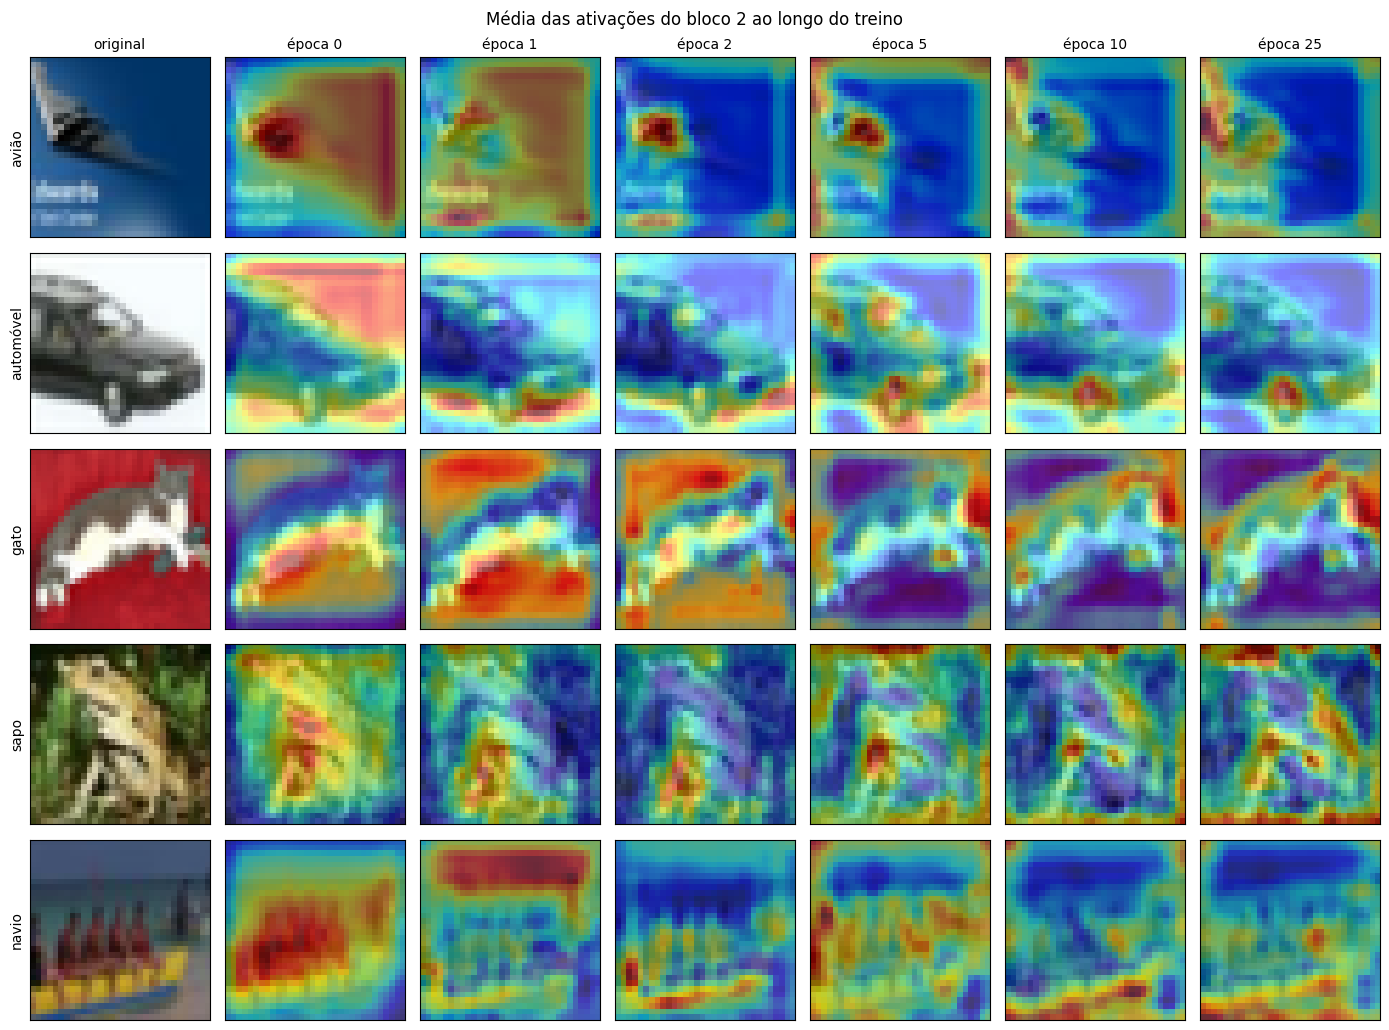

In [24]:
def block2_mean(model, x):
    acts = {}
    h = model.block2[1].register_forward_hook(lambda m, i, o: acts.__setitem__("a", o.detach()))
    with torch.no_grad(): model(x.to(DEVICE))
    h.remove()
    a = acts["a"].mean(1, keepdim=True)
    a = F.interpolate(a, size=32, mode="bilinear", align_corners=False)[:, 0]
    a = a - a.amin((1, 2), keepdim=True); return (a / (a.amax((1, 2), keepdim=True) + 1e-8)).cpu()

maps = {ep: block2_mean(load_ckpt(ep), Xte_n[sel]) for ep in CKPTS}
fig, axes = plt.subplots(len(sel), len(CKPTS) + 1, figsize=(2 * (len(CKPTS) + 1), 2.1 * len(sel)))
for r, idx in enumerate(sel):
    img = denorm(Xte_n[idx]).permute(1, 2, 0).numpy()
    axes[r, 0].imshow(img); axes[r, 0].set_ylabel(CLASSES[yte[idx]], fontsize=10)
    for c, ep in enumerate(CKPTS, start=1):
        axes[r, c].imshow(img); axes[r, c].imshow(maps[ep][r].numpy(), cmap="jet", alpha=0.5)
        if r == 0: axes[r, c].set_title(f"época {ep}", fontsize=10)
    if r == 0: axes[r, 0].set_title("original", fontsize=10)
for a in axes.flat: a.set_xticks([]); a.set_yticks([])
plt.suptitle("Média das ativações do bloco 2 ao longo do treino"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4evo_ativacoes_bloco2.png", dpi=120); plt.show()

**Leitura (ativações do bloco 2):**
- **Época 0 (pesos aleatórios):** a camada já responde à imagem, mas de forma **grosseira**: manchas que seguem brilho e cor (o fundo vermelho do gato, a região escura do avião, o bloco colorido de pessoas no navio). Sem treino, a convolução ainda funciona como um "filtro passa-baixa" aleatório.
- **Épocas 1–2:** os mapas começam a desenhar **contornos** (o dorso do gato, a silhueta do carro, a linha do casco), mas o fundo ainda ativa bastante (o vermelho atrás do gato na época 1).
- **Épocas 5–25:** a resposta se concentra nas **bordas e partes do objeto** (contorno do gato, rodas do carro, casco e pessoas no navio, textura do sapo), e as **áreas uniformes do fundo são suprimidas** (céu do avião, fundo vermelho do gato e parede branca atrás do carro ficam com ativação baixa).
- O **artefato de borda** (margens acesas pelo *zero-padding*), comentado na Q4(b), fica mais evidente com o treino (por exemplo, a borda superior e inferior do sapo e a lateral direita do gato nas épocas 10–25).


### Grad-CAM ao longo do treino
Regiões que mais contribuem para a **classe verdadeira** (Grad-CAM no bloco 3), com a probabilidade que o checkpoint atribui à classe verdadeira.

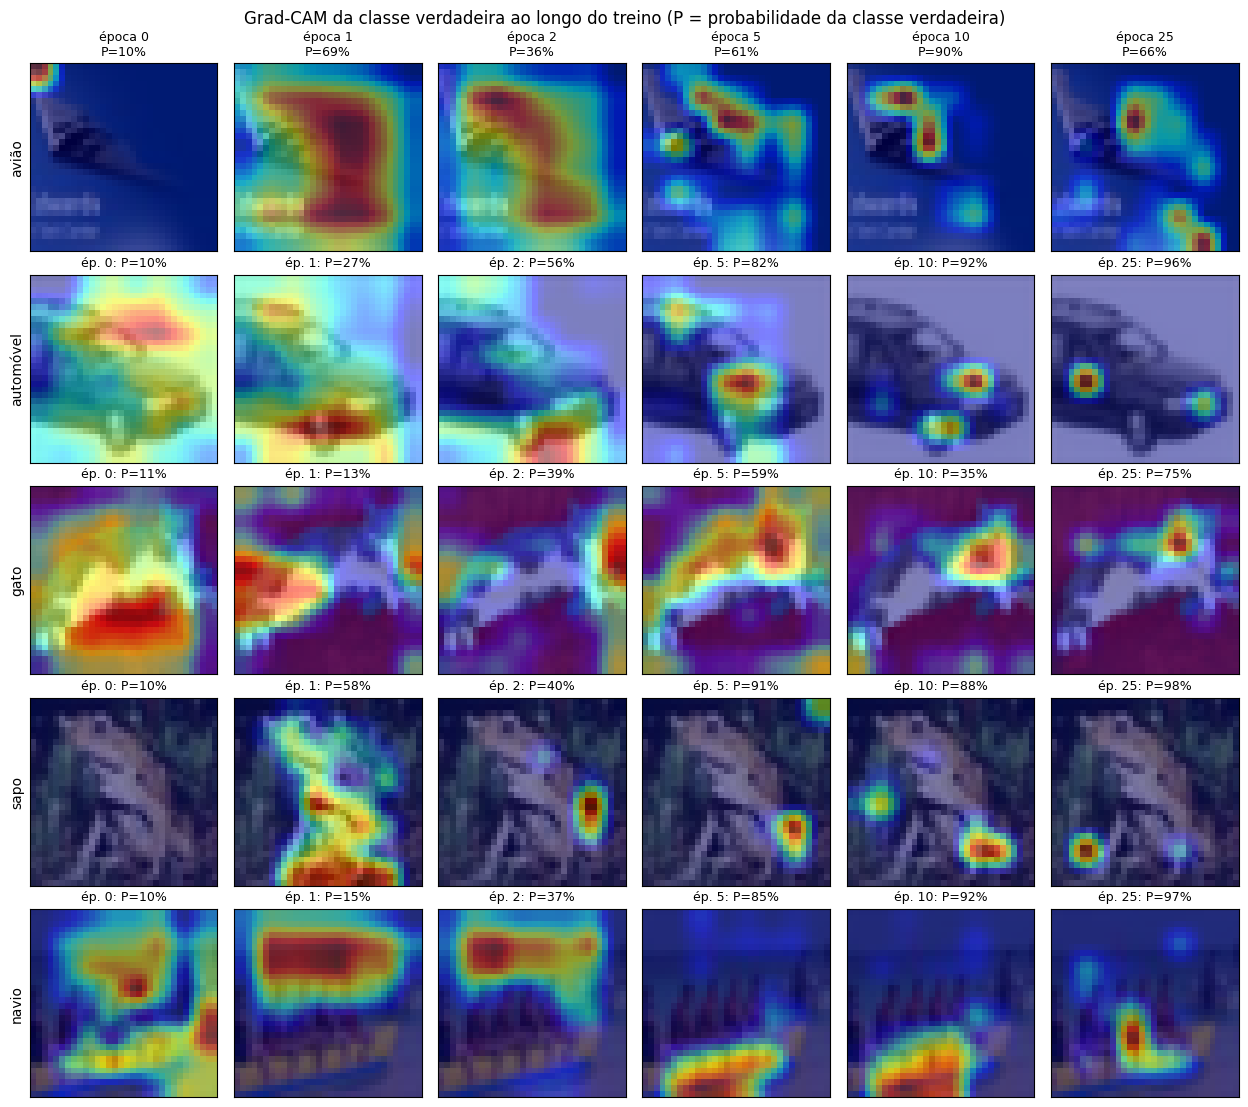

,época 0,época 1,época 2,época 5,época 10,época 25
avião,10.1%,68.5%,36.4%,61.2%,90.4%,65.7%
automóvel,10.2%,26.6%,56.2%,81.6%,92.2%,95.7%
gato,10.5%,12.5%,39.0%,59.1%,34.9%,75.3%
sapo,9.7%,58.1%,40.4%,90.7%,87.9%,97.6%
navio,10.1%,14.7%,36.9%,85.2%,92.1%,97.5%


In [25]:
def grad_cam_alvo(model, x, target_layer, target):
    """Como grad_cam da Q4(b), mas para a classe VERDADEIRA (target), não a predita."""
    store = {}
    def fwd(m, i, o):
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    fh = target_layer.register_forward_hook(fwd)
    model.eval(); out = model(x.to(DEVICE))
    model.zero_grad(); out.gather(1, target.to(DEVICE)[:, None]).sum().backward(); fh.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=32, mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin((1, 2), keepdim=True); cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu(), out.softmax(1).detach().cpu()

fig, axes = plt.subplots(len(sel), len(CKPTS), figsize=(2.1 * len(CKPTS), 2.25 * len(sel)))
ptab = {}
for c, ep in enumerate(CKPTS):
    m = load_ckpt(ep); cams, pr = grad_cam_alvo(m, Xte_n[sel], m.block3[1], yte[sel])
    ptab[f"época {ep}"] = [pr[r, yte[idx]].item() for r, idx in enumerate(sel)]
    for r, idx in enumerate(sel):
        img = denorm(Xte_n[idx]).permute(1, 2, 0).numpy()
        axes[r, c].imshow(img); axes[r, c].imshow(cams[r].numpy(), cmap="jet", alpha=0.5)
        axes[r, c].set_title(f"ép. {ep}: P={pr[r, yte[idx]]:.0%}", fontsize=9); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[0, c].set_title(f"época {ep}\nP={ptab[f'época {ep}'][0]:.0%}", fontsize=9)
for r, idx in enumerate(sel): axes[r, 0].set_ylabel(CLASSES[yte[idx]], fontsize=10)
plt.suptitle("Grad-CAM da classe verdadeira ao longo do treino (P = probabilidade da classe verdadeira)"); plt.tight_layout()
plt.savefig(FIG_DIR / "q4evo_gradcam.png", dpi=120); plt.show()
display(pd.DataFrame(ptab, index=[CLASSES[yte[i]] for i in sel]).style.format("{:.1%}"))

**Leitura (Grad-CAM):**
- **Época 0:** o mapa é arbitrário e a probabilidade é ≈ 10% para todas as imagens (chute uniforme entre 10 classes).
- **Épocas 1–2:** os mapas são **manchas grandes e difusas**, que muitas vezes cobrem o fundo (no navio, a faixa de céu/mar; no sapo, quase o corpo todo junto com a vegetação). A rede já acerta acima do acaso, mas decide por **cor e região grossa**, não por partes do objeto.
- **Épocas 5–25:** o Grad-CAM **se concentra em partes do objeto**: a **cabeça do gato** (mesma região da CNN analisada na Q4(b)), o **casco** do navio, as **patas/parte de baixo** do sapo e a **frente/farol e a região das rodas** do automóvel (na CNN da Q4(b), as rodas quase não apareciam: mais um exemplo da variação entre execuções discutida abaixo).
- **Atalhos espúrios aparecem cedo e persistem:** no avião, além da fuselagem, a versão final também acende num **canto do fundo** (inferior direito). Na CNN da Q3, o foco espúrio estava na marca d'água (inferior esquerdo). Execuções diferentes da mesma receita podem escolher **evidências diferentes** para a mesma imagem, o que é um alerta para não interpretar um único mapa como "a" explicação.
- **A confiança não cresce de forma monótona por imagem** (gato: 59% → 35% → 75%; avião: 90% na época 10 e 66% na 25), mas a **média** sobe de forma consistente (10% → 36% → 42% → 76% → 80% → 86%). Ao longo do treino, a rede troca de evidência para algumas imagens enquanto melhora no conjunto.

### Conclusões do item (d)
1. **As representações surgem em ordem: cor/região → contorno → partes discriminativas.** Nas primeiras épocas, a rede usa manchas de cor e o fundo; a partir da época ~5, o bloco 2 passa a seguir contornos e o Grad-CAM se concentra em partes do objeto.
2. **As camadas iniciais estabilizam primeiro** (conv1 com cos = 0,97 na época 10, contra 0,74 da camada densa), e são as que mais **guardam da inicialização**, o que explica os filtros ruidosos da Q4(a).
3. A mesma receita reproduz o desempenho (89,1% × 88,9% no teste), mas os detalhes do que a rede "olha" variam entre execuções.


## Conclusões gerais
1. Para imagens, o viés indutivo da convolução (localidade + compartilhamento de pesos) vale mais do que "força bruta" de parâmetros: a CNN tem menos parâmetros e acerta muito mais.
2. A CNN aprende uma hierarquia: a 1ª camada decompõe a imagem em bordas e regiões de cor; as camadas intermediárias combinam isso em contornos e texturas; as finais decidem com base em regiões discriminativas do objeto e, às vezes, em atalhos espúrios (fundo, marca d'água), que o Grad-CAM ajuda a detectar. O item (d) mostra que essa hierarquia **se forma nessa mesma ordem** durante o treino: cor/região nas primeiras épocas, contornos a partir da época ~5 e partes discriminativas no fim, com as camadas iniciais estabilizando primeiro.
3. Melhorias possíveis: redes mais profundas (ResNet), mais épocas, augmentation mais forte (Cutout/MixUp), *test-time augmentation*.